# 09 · Aprendizaje automático científico: PINN y operadores neuronales

Este es un módulo de **Neural Networks 1002**. Supone conocidos el [módulo 02 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/02-retropropagacion/) (retropropagación, que aquí se convierte en la **diferenciación automática** de la red respecto de sus *entradas*) y el [módulo 03](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) (entrenar bien: Adam, planes de tasa de aprendizaje, por qué una pérdida mal escalada es difícil de optimizar).

La simulación de un flujo, de una estructura que vibra o de un cuerpo que conduce calor es un programa que resuelve una ecuación. Ese programa es preciso, pero puede ser lento (horas en un clúster para una sola ejecución), necesita que la ecuación, la geometría y el estado inicial se conozcan con exactitud, y hay que ejecutarlo otra vez para cada caso nuevo. Una red neuronal es lo contrario: rápida una vez entrenada, flexible, pero hambrienta de datos y sin idea de física. El **aprendizaje automático científico** (SciML, de scientific machine learning) es la familia de métodos que combinan ambas cosas. En este cuaderno construirás, solo con PyTorch y en la CPU de un portátil, con semillas fijas y con cada afirmación medida:

1. un **solver numérico clásico** (diferencias finitas) para la ecuación del calor, con su precisión, su orden de convergencia y su coste, porque todo método neuronal posterior debe compararse con él;
2. una **red neuronal informada por la física** (PINN, de physics-informed neural network) para una ecuación diferencial ordinaria (un oscilador amortiguado), donde la ecuación entra en la pérdida mediante diferenciación automática, con el efecto de los **pesos de la pérdida** y de las **restricciones duras**, y un caso con pocas mediciones ruidosas en el que la física rescata una extrapolación;
3. una PINN para una **ecuación en derivadas parciales** (la ecuación del calor 1D) con condiciones de contorno e iniciales, con el error medido frente a la solución exacta y frente al solver de diferencias finitas, en precisión y en segundos;
4. el **problema inverso**: identificar el coeficiente de difusión a partir de mediciones ruidosas, comparado con el ajuste clásico por mínimos cuadrados, como error del parámetro frente al nivel de ruido;
5. los **modos de fallo conocidos** de las PINN, mostrados y medidos: sesgo espectral (y el remedio de los rasgos de Fourier), desequilibrio de la pérdida (y los pesos adaptativos) y problemas rígidos o de horizonte largo (y el entrenamiento causal);
6. los **operadores neuronales**, que aprenden la aplicación que lleva una condición inicial a la solución en lugar de una sola solución: una **DeepONet** (deep operator network, red de operadores profunda) pequeña y un **operador neuronal de Fourier** (FNO, de Fourier neural operator) pequeño para la ecuación de Burgers viscosa, con datos de entrenamiento de nuestro propio solver, probados con condiciones iniciales nuevas, con una malla más fina y frente a la velocidad del solver;
7. una **tabla de decisión** (solver, PINN, operador neuronal o híbrido) y un repaso honesto de los grandes modelos científicos (tiempo atmosférico, proteínas, materiales).

**Contenido**

1. Por qué el aprendizaje automático científico
2. La referencia: un solver clásico
3. PINN desde cero: una ecuación diferencial ordinaria
4. PINN para la ecuación del calor
5. El problema inverso: identificar un parámetro a partir de datos ruidosos
6. Cuándo fallan las PINN y los remedios
7. Operadores neuronales: aprender la aplicación solución
8. Qué herramienta para qué problema
9. Grandes modelos científicos: qué está establecido
10. Ideas clave, ejercicios, referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| [02 Red neuronal y retropropagación (1001)](https://neural-networks.academy.forwardforecasting.eu/es/02-retropropagacion/) | autograd: la misma maquinaria que da el gradiente respecto de los pesos da la derivada de la salida respecto de la entrada |
| [03 Entrenar redes profundas (1001)](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) | Adam, decaimiento de la tasa de aprendizaje, escala de la pérdida y por qué hay que equilibrar varios términos de pérdida |

¿Nuevo en PyTorch? El [curso Python 1001, sección sobre frameworks de IA](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/) lo presenta. Todos los datos se generan en el cuaderno (sin descargas), solo se usan NumPy, SciPy, matplotlib y PyTorch (todos preinstalados en Google Colab) y el cuaderno usa dos hilos. **Tiempo:** unos 11 minutos de principio a fin en una ejecución de 2 hilos en nuestro clúster (compartido); en un entorno gratuito de Colab con 2 vCPU espera algo más, no lo hemos medido. Las etapas L-BFGS y las ejecuciones de convección de la sección 6.3 son las celdas más lentas. La física aquí es deliberadamente genérica y pequeña (un oscilador, conducción de calor en una barra, la ecuación de Burgers para un fluido unidimensional); las mismas ideas se trasladan a problemas mayores donde, como muestra el repaso de la sección 9, las preguntas abiertas son sobre todo de escala y de evidencia.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/09_aprendizaje_automatico_cientifico.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 9 minutos, con un pico de memoria de menos de 1 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'scipy': 'scipy',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.linalg import solve_banded
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.interpolate import RegularGridInterpolator

import os
torch.set_num_threads(min(2, os.cpu_count() or 2))        # dos hilos: lo que ofrece un entorno gratuito de Colab
torch.manual_seed(0); np.random.seed(0); random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 100
T_START = time.time()

def mlp(sizes, act=nn.Tanh):
    # un perceptrón multicapa simple con inicialización de Xavier (la elección habitual para PINN con tanh)
    layers = []
    for i in range(len(sizes) - 1):
        layers.append(nn.Linear(sizes[i], sizes[i + 1]))
        if i < len(sizes) - 2:
            layers.append(act())
    net = nn.Sequential(*layers)
    for m in net:
        if isinstance(m, nn.Linear):
            nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    return net

def d(y, x):
    # derivada de y respecto de x, que sigue siendo derivable para poder derivar otra vez
    return torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]

def rel_l2(pred, true):
    # error L2 relativo: norma de la diferencia dividida por la norma de la solución verdadera
    return float(np.linalg.norm(np.asarray(pred) - np.asarray(true)) / np.linalg.norm(true))

## 1. Por qué el aprendizaje automático científico

Tres situaciones empujan a pasar de un solver simple o de una red simple a una mezcla de ambos.

* **Simulaciones caras.** Una simulación meteorológica, de combustión o de choque puede tardar horas por escenario. Si hay que evaluar miles de escenarios (optimización de diseño, cuantificación de incertidumbre, control en tiempo real), vale la pena un **sustituto** (surrogate) rápido que imite al simulador. Una red entrenada con la salida del simulador es ese sustituto, y un **operador neuronal** (sección 7) es la versión que sirve para toda una familia de entradas.
* **Pocos datos, física conocida.** Tienes un puñado de sensores ruidosos pero conoces la ley que rige el fenómeno salvo unas constantes. Una red simple ajusta los puntos y extrapola disparates; un modelo obligado a respetar la ley necesita muchos menos puntos. Esta es la idea de la **PINN** (Raissi, Perdikaris y Karniadakis, 2019): meter la ecuación en la pérdida.
* **Parámetros desconocidos o términos que faltan.** La ecuación vale, pero un coeficiente (una difusividad, un coeficiente de amortiguamiento, una viscosidad) no se conoce y hay que inferirlo de mediciones: un **problema inverso**.

Hay además una advertencia que conviene llevar a lo largo de todo el cuaderno. El solver clásico es una referencia muy fuerte: para un problema directo bien planteado suele ser **más preciso y más barato** que una PINN, y se ha visto que las afirmaciones publicadas de grandes aceleraciones de solvers neuronales de EDP descansan en referencias débiles (McGreivy y Hakim, 2024; Grossmann et al., 2024; ambos en las referencias). Los métodos neuronales se ganan su sitio donde el solver es demasiado lento para llamarlo muchas veces, donde hay que combinar datos y física o donde el problema es inverso; medimos cada caso en lugar de suponerlo.

| Método | Qué aprende | ¿Necesita la ecuación? | ¿Necesita datos de simulación? | Un modelo entrenado cubre |
|---|---|---|---|---|
| solver clásico | nada (calcula) | sí | no | un caso por ejecución |
| PINN | una solución (o un parámetro) | sí, en la pérdida | no, o unas pocas mediciones | un caso |
| operador neuronal | la aplicación de entradas a soluciones | no | sí, muchas ejecuciones del solver | toda una familia de casos |
| híbrido | una corrección o un término que falta | en parte | algunos | depende |

## 2. La referencia: un solver clásico

Nuestro primer problema de prueba es la **conducción de calor en una barra delgada** de longitud 1 con sus dos extremos a temperatura cero:

$$\frac{\partial u}{\partial t} = \nu\,\frac{\partial^2 u}{\partial x^2},\qquad u(0,t)=u(1,t)=0,\qquad u(x,0)=\sin(\pi x)+\tfrac12\sin(3\pi x),$$

donde $u(x,t)$ es la temperatura en la posición $x$ y el instante $t$, y $\nu$ (la letra griega nu) es el **coeficiente de difusión** (la rapidez con que se propaga el calor; usamos $\nu=0.05$). La solución exacta se conoce, porque cada seno decae a su propio ritmo:

$$u(x,t)=e^{-\nu\pi^2 t}\sin(\pi x)+\tfrac12 e^{-9\nu\pi^2 t}\sin(3\pi x).$$

Tener una respuesta exacta nos permite medir con honestidad el error de cada método. El **método de diferencias finitas** sustituye las derivadas por diferencias en una malla de $n_x$ celdas (ancho de celda $\Delta x=1/n_x$) y $n_t$ pasos de tiempo (paso $\Delta t=1/n_t$). Programamos dos esquemas clásicos: **FTCS** (forward time, centred space, tiempo hacia delante y espacio centrado), que es explícito y solo es estable cuando $r=\nu\Delta t/\Delta x^2\le 1/2$, y **Crank-Nicolson** (CN), que promedia el nivel de tiempo viejo y el nuevo, es incondicionalmente estable y tiene precisión de segundo orden tanto en $\Delta x$ como en $\Delta t$.

Crank-Nicolson, dt = dx, error en t = 1 (máximo sobre la malla)
   nx  error máx.  orden tiempo (ms)
   10    3.08e-03             0.220
   20    7.26e-04   2.08      0.390
   40    1.79e-04   2.02      0.780
   80    4.48e-05   2.00      1.600
  160    1.12e-05   2.00      3.503
  320    2.80e-06   2.00      8.642
FTCS nx=50 nt=50 r=2.50: máx |u| en t=1 = 1.87e+31 (máx exacto 0.605)
FTCS nx=50 nt=500 r=0.25: máx |u| en t=1 = 0.605 (máx exacto 0.605)
oscilador RK45 rtol=0.001: error L2 relativo 1.5e-03, 1.29 ms
oscilador RK45 rtol=1e-06: error L2 relativo 8.9e-07, 4.68 ms


oscilador RK45 rtol=1e-09: error L2 relativo 8.0e-10, 17.10 ms


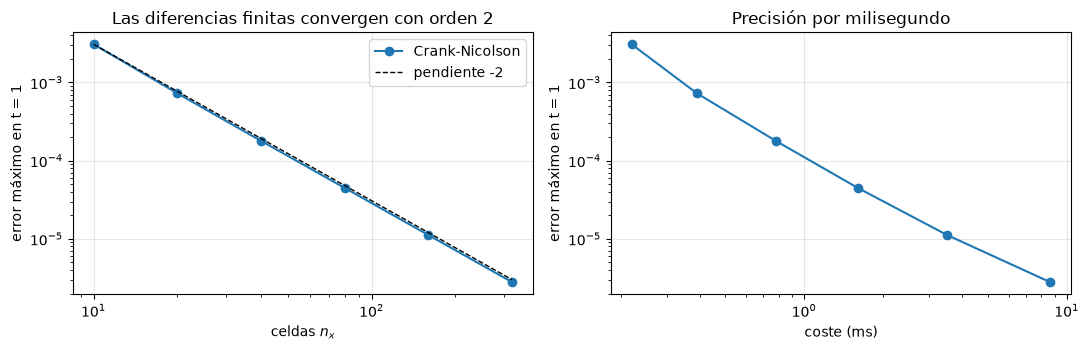

In [2]:
NU = 0.05                                    # coeficiente de difusión de la ecuación del calor

def u0_heat(x):
    return np.sin(np.pi * x) + 0.5 * np.sin(3 * np.pi * x)

def heat_exact(x, t, nu=NU):
    return (np.exp(-nu * np.pi**2 * t) * np.sin(np.pi * x)
            + 0.5 * np.exp(-9 * nu * np.pi**2 * t) * np.sin(3 * np.pi * x))

def heat_fd(nx, nt, nu=NU, T=1.0, scheme="cn", u0=u0_heat, keep=False):
    # diferencias finitas para u_t = nu u_xx en [0,1], extremos a cero. Devuelve x, u(T) (y todos los niveles de tiempo si keep)
    x = np.linspace(0, 1, nx + 1); dx = 1.0 / nx; dt = T / nt; r = nu * dt / dx**2
    u = u0(x).astype(float); hist = [u.copy()]
    if scheme == "cn":
        n = nx - 1
        ab = np.zeros((3, n)); ab[0, 1:] = -r / 2; ab[1, :] = 1 + r; ab[2, :-1] = -r / 2   # matriz banda de la mitad implícita
    for _ in range(nt):
        lap = u[2:] - 2 * u[1:-1] + u[:-2]
        if scheme == "ftcs":
            u[1:-1] = u[1:-1] + r * lap
        else:
            u[1:-1] = solve_banded((1, 1), ab, u[1:-1] + r / 2 * lap)
        if keep: hist.append(u.copy())
    return (x, u, np.array(hist)) if keep else (x, u)

def timed(f, reps=20):
    t0 = time.perf_counter()
    for _ in range(reps): out = f()
    return out, (time.perf_counter() - t0) / reps

rows = []
for nx in [10, 20, 40, 80, 160, 320]:
    (x, u), sec = timed(lambda: heat_fd(nx, nx, scheme="cn"))              # paso de tiempo = ancho de celda
    err = np.abs(u - heat_exact(x, 1.0)).max()
    rows.append((nx, err, sec))
print("Crank-Nicolson, dt = dx, error en t = 1 (máximo sobre la malla)")
print(f"{'nx':>5} {'error máx.':>11} {'orden':>6} {'tiempo (ms)':>11}")
for i, (nx, err, sec) in enumerate(rows):
    order = "" if i == 0 else f"{np.log2(rows[i-1][1] / err):.2f}"
    print(f"{nx:>5} {err:>11.2e} {order:>6} {sec*1e3:>10.3f}")

# esquema explícito: estable solo si r <= 1/2
for nx, nt in [(50, 50), (50, 500)]:
    x, u = heat_fd(nx, nt, scheme="ftcs")
    r = NU * (1.0 / nt) / (1.0 / nx) ** 2
    print(f"FTCS nx={nx} nt={nt} r={r:.2f}: máx |u| en t=1 = {np.abs(u).max():.3g} (máx exacto {np.abs(heat_exact(x, 1.0)).max():.3f})")

# el oscilador resuelto con un Runge-Kutta adaptativo estándar, para la sección siguiente
W0, ZETA = 2.0, 0.1                          # frecuencia angular natural y coeficiente de amortiguamiento
def osc_exact(t, w0=W0, zeta=ZETA):
    a = zeta * w0; wd = w0 * np.sqrt(1 - zeta**2)
    return np.exp(-a * t) * (np.cos(wd * t) + a / wd * np.sin(wd * t))
tt = np.linspace(0, 10, 500)
for rtol in [1e-3, 1e-6, 1e-9]:
    sol, sec = timed(lambda: solve_ivp(lambda t, y: [y[1], -2 * ZETA * W0 * y[1] - W0**2 * y[0]], (0, 10), [1.0, 0.0],
                                       t_eval=tt, rtol=rtol, atol=rtol * 1e-3, method="RK45"))
    print(f"oscilador RK45 rtol={rtol:g}: error L2 relativo {rel_l2(sol.y[0], osc_exact(tt)):.1e}, {sec*1e3:.2f} ms")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
nxs = np.array([r_[0] for r_ in rows]); errs = np.array([r_[1] for r_ in rows]); secs = np.array([r_[2] for r_ in rows])
ax[0].loglog(nxs, errs, "o-", label="Crank-Nicolson"); ax[0].loglog(nxs, errs[0] * (nxs[0] / nxs) ** 2, "k--", lw=1, label="pendiente -2")
ax[0].set_xlabel("celdas $n_x$"); ax[0].set_ylabel("error máximo en t = 1"); ax[0].legend(); ax[0].set_title("Las diferencias finitas convergen con orden 2")
ax[1].loglog(secs * 1e3, errs, "o-"); ax[1].set_xlabel("coste (ms)"); ax[1].set_ylabel("error máximo en t = 1"); ax[1].set_title("Precisión por milisegundo")
plt.tight_layout(); plt.show()

**Lectura.** Los dos esquemas se comportan como dice la teoría. Crank-Nicolson muestra un orden observado de 2.00 (el error se divide por cuatro al refinar la malla al doble), desde 3e-3 con 10 celdas hasta 2.8e-6 con 320 celdas en 9 ms, y el esquema explícito es estable con $r=0.25$ y explota (valores de 1e31) con $r=2.5$. El solver adaptativo de Runge-Kutta llega a 9e-7 en el oscilador en menos de 5 ms. Estos son los números que debe superar un método neuronal: un solver con error de 1e-5 o 1e-6 en pocos milisegundos, con orden de convergencia conocido y una condición de estabilidad. Tenlos presentes en cada tabla posterior. (Los tiempos son de reloj en una máquina compartida y varían unas pocas decenas por ciento.)

## 3. PINN desde cero: una ecuación diferencial ordinaria

Una **red neuronal informada por la física** representa la solución desconocida con una red $x_\theta(t)$ (con pesos $\theta$, la letra griega theta) y la entrena para que el *residuo* de la ecuación sea pequeño en muchos **puntos de colocación** (puntos donde ponemos a prueba la ecuación). Empezamos con la ecuación más simple: un **oscilador amortiguado**, una masa en un muelle con rozamiento,

$$\ddot x + 2\zeta\omega_0\,\dot x+\omega_0^2\,x = 0,\qquad x(0)=1,\ \dot x(0)=0,$$

donde $x(t)$ es el desplazamiento, $\dot x$ y $\ddot x$ sus derivadas primera y segunda respecto del tiempo, $\omega_0$ la frecuencia angular natural ($\omega_0=2$) y $\zeta$ (zeta) el coeficiente de amortiguamiento ($\zeta=0.1$, poco amortiguado). El **residuo** es el lado izquierdo evaluado sobre la red; la **diferenciación automática** da $\dot x_\theta$ y $\ddot x_\theta$ exactamente, sin diferencias finitas. La pérdida es

$$\mathcal L=\underbrace{\frac1{N_c}\sum_i\big(\ddot x_\theta(t_i)+2\zeta\omega_0\dot x_\theta(t_i)+\omega_0^2x_\theta(t_i)\big)^2}_{\text{residuo físico}}+\lambda\,\underbrace{\big[(x_\theta(0)-1)^2+\dot x_\theta(0)^2\big]}_{\text{condiciones iniciales}},$$

con $N_c=200$ puntos de colocación en $[0,10]$ y un peso $\lambda$ (lambda) que decide cuánto cuentan las condiciones iniciales. Sin ellas la red puede aprender la solución trivial $x\equiv0$, que también cumple la ecuación. Hay una alternativa a la penalización blanda: una **restricción dura**, escribiendo $x_\theta(t)=1+t^2\,N_\theta(t)$, que cumple $x(0)=1$ y $\dot x(0)=0$ para cualquier red $N_\theta$ por construcción.

La optimización tiene dos etapas, la receta habitual de las PINN: 3,000 pasos de **Adam** y luego hasta 500 iteraciones de **L-BFGS** (limited-memory Broyden-Fletcher-Goldfarb-Shanno, un método cuasi-Newton que usa la curvatura y necesita un conjunto fijo de puntos, de modo que pule lo que encontró Adam). Comparamos $\lambda\in\{0.01,1,100\}$ y la restricción dura con dos semillas, y medimos el error L2 relativo frente a la solución exacta en $[0,10]$. (Dentro de la red el tiempo se reescala a $t/10$, una forma habitual de mantener las entradas de una red tanh en un buen rango.)

soft, lambda = 1     error L2 relativo por semilla: 4.21e-03, 1.25e-01   (7.7 s por ejecución)


soft, lambda = 100   error L2 relativo por semilla: 4.61e-01, 4.23e-01   (7.4 s por ejecución)


hard constraint      error L2 relativo por semilla: 2.43e-01, 1.43e-01   (7.2 s por ejecución)


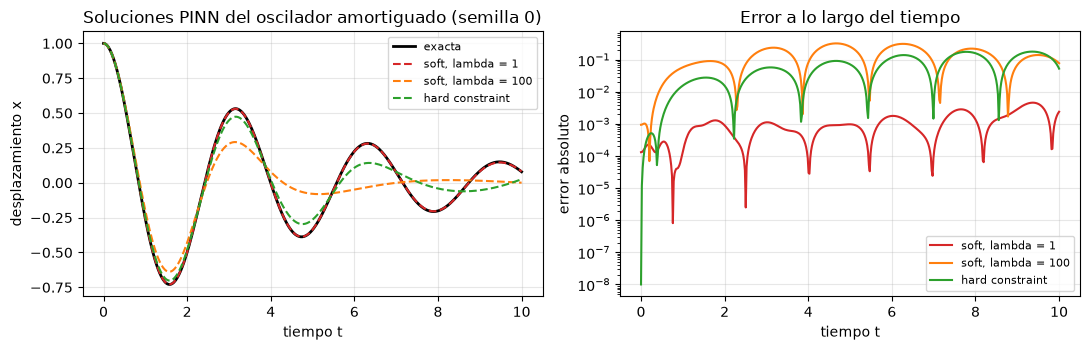

In [3]:
def train_osc(mode, seed, w_ic=1.0, steps=3000, obs=None, w_data=1.0):
    # mode: "soft" (penalización de las condiciones iniciales), "hard" (restricción por construcción),
    #       "data" (solo ajusta las observaciones), "phys+data" (residuo + observaciones, SIN condiciones iniciales)
    torch.manual_seed(seed)
    net = mlp([1, 32, 32, 32, 1])
    f = (lambda t: 1.0 + (t / 10) ** 2 * net(t / 10) * 10) if mode == "hard" else (lambda t: net(t / 10))   # dentro de la red el tiempo se reescala a [0, 1]
    tc = torch.linspace(0, 10, 200).reshape(-1, 1).requires_grad_(True)
    t0 = torch.zeros(1, 1, requires_grad=True)
    if obs is not None:
        to = torch.tensor(obs[0], dtype=torch.float32).reshape(-1, 1); xo = torch.tensor(obs[1], dtype=torch.float32).reshape(-1, 1)
    def loss_fn():
        loss = 0.0
        if mode in ("soft", "hard", "phys+data"):
            x = f(tc); dx = d(x, tc); ddx = d(dx, tc)
            loss = ((ddx + 2 * ZETA * W0 * dx + W0**2 * x) ** 2).mean()          # residuo físico
        if mode == "soft":
            x0 = f(t0); loss = loss + w_ic * ((x0 - 1) ** 2 + d(x0, t0) ** 2).sum()
        if mode in ("data", "phys+data"):
            loss = loss + w_data * ((f(to) - xo) ** 2).mean()
        return loss
    t_start = time.perf_counter()
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / steps))
    for s in range(steps):                                                       # etapa 1: Adam
        opt.zero_grad(); loss_fn().backward(); opt.step(); sched.step()
    lbfgs = torch.optim.LBFGS(net.parameters(), lr=1, max_iter=500, history_size=50, line_search_fn="strong_wolfe")
    def closure():                                                               # etapa 2: pulido con L-BFGS, la receta habitual de las PINN
        lbfgs.zero_grad(); l = loss_fn(); l.backward(); return l
    lbfgs.step(closure)
    sec = time.perf_counter() - t_start
    with torch.no_grad():
        tt_ = torch.tensor(tt, dtype=torch.float32).reshape(-1, 1)
        pred = f(tt_).numpy().ravel()
    return pred, sec

tt = np.linspace(0, 10, 500)
xt = osc_exact(tt)
results_osc = {}
for name, kw in [("soft, lambda = 1", dict(mode="soft", w_ic=1.0)), ("soft, lambda = 100", dict(mode="soft", w_ic=100.0)),
                 ("hard constraint", dict(mode="hard"))]:
    errs, secs = [], []
    for seed in range(2):
        pred, sec = train_osc(seed=seed, **kw)
        errs.append(rel_l2(pred, xt)); secs.append(sec); results_osc[(name, seed)] = pred
    print(f"{name:20s} error L2 relativo por semilla: {errs[0]:.2e}, {errs[1]:.2e}   ({np.mean(secs):.1f} s por ejecución)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(tt, xt, "k", lw=2, label="exacta")
for name, c in [("soft, lambda = 1", "tab:red"), ("soft, lambda = 100", "tab:orange"), ("hard constraint", "tab:green")]:
    ax[0].plot(tt, results_osc[(name, 0)], "--", color=c, label=name)
ax[0].set_xlabel("tiempo t"); ax[0].set_ylabel("desplazamiento x"); ax[0].legend(fontsize=8); ax[0].set_title("Soluciones PINN del oscilador amortiguado (semilla 0)")
for name, c in [("soft, lambda = 1", "tab:red"), ("soft, lambda = 100", "tab:orange"), ("hard constraint", "tab:green")]:
    ax[1].semilogy(tt, np.abs(results_osc[(name, 0)] - xt) + 1e-8, color=c, label=name)
ax[1].set_xlabel("tiempo t"); ax[1].set_ylabel("error absoluto"); ax[1].legend(fontsize=8); ax[1].set_title("Error a lo largo del tiempo")
plt.tight_layout(); plt.show()

**Lectura.** Es un resultado mixto y la lectura honesta es que el entrenamiento de una PINN es frágil. Con $\lambda=1$ el mismo código dio un error de 0.4 % con la semilla 0 y de 12 % con la semilla 1, una dispersión de 30 veces causada solo por la inicialización aleatoria. Un peso grande ($\lambda=100$) fue claramente peor (error de unos 45 %): la red cumple las condiciones iniciales y luego no logra cumplir la ecuación. La restricción dura, que elimina el peso por completo, no fue mejor aquí (14 % a 24 %); el optimizador aún tiene que encontrar la oscilación. Incluso la mejor ejecución (0.4 %) tarda unos 7 s, mientras que el solver de Runge-Kutta de la sección 2 tiene un error de 9e-7 en 5 ms. Con dos semillas nada de esto es un ranking de métodos; el mensaje es que el error depende de los pesos, de la restricción y de la semilla en factores de 10 a 100.

### Datos escasos y ruidosos: donde la física compensa

Ahora la situación que motiva las PINN. Observamos el oscilador solo en **8 instantes aleatorios en $[0,5]$**, con ruido gaussiano de desviación típica 0.05, y queremos toda la trayectoria en $[0,10]$, incluida la mitad donde no tenemos datos. **No damos las condiciones iniciales**: la ecuación se conoce pero el estado de partida no. Se entrenan dos modelos con la misma red: **solo datos** (error cuadrático medio en los 8 puntos) y **física más datos** (la pérdida del residuo más el mismo término de datos). La física restringe la *forma* de cualquier solución admisible y los datos eligen cuál.

modelo              error en [0,5] (zona con datos)    error en (5,10] (extrapolación)
data only                       1.410 +- 1.430                   18.470 +- 16.601
physics + data                  0.110 +- 0.058                    0.107 +- 0.041


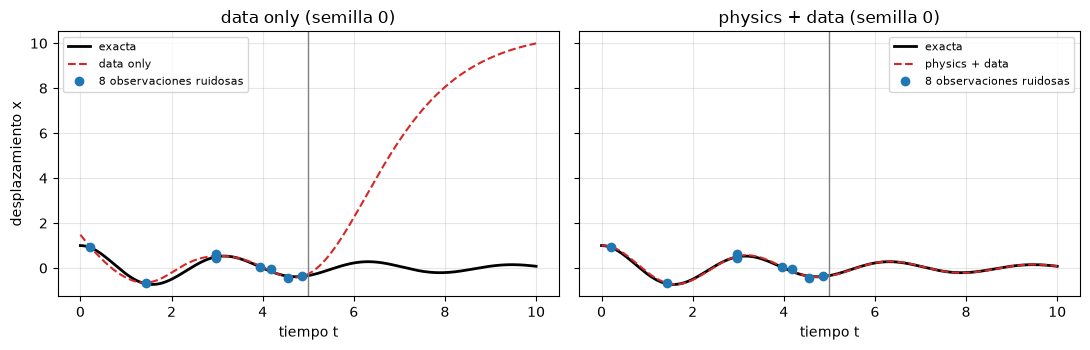

In [4]:
rng = np.random.default_rng(0)
errs_in, errs_out = {"data only": [], "physics + data": []}, {"data only": [], "physics + data": []}
example = {}
for seed in range(3):
    r_ = np.random.default_rng(100 + seed)
    to = np.sort(r_.uniform(0, 5, 8)); xo = osc_exact(to) + 0.05 * r_.normal(size=8)
    for name, mode in [("data only", "data"), ("physics + data", "phys+data")]:
        pred, _ = train_osc(mode, seed, steps=3000, obs=(to, xo), w_data=10.0)
        errs_in[name].append(rel_l2(pred[tt <= 5], xt[tt <= 5])); errs_out[name].append(rel_l2(pred[tt > 5], xt[tt > 5]))
        if seed == 0: example[name] = (pred, to, xo)
print(f"{'modelo':16s} {'error en [0,5] (zona con datos)':>34s} {'error en (5,10] (extrapolación)':>34s}")
for name in errs_in:
    print(f"{name:16s} {np.mean(errs_in[name]):>20.3f} +- {np.std(errs_in[name]):.3f}   {np.mean(errs_out[name]):>22.3f} +- {np.std(errs_out[name]):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for a, name in zip(ax, ["data only", "physics + data"]):
    pred, to, xo = example[name]
    a.plot(tt, xt, "k", lw=2, label="exacta"); a.plot(tt, pred, "--", color="tab:red", label=name); a.plot(to, xo, "o", color="tab:blue", label="8 observaciones ruidosas")
    a.axvline(5, color="gray", lw=1); a.set_xlabel("tiempo t"); a.set_title(name + " (semilla 0)"); a.legend(fontsize=8)
ax[0].set_ylabel("desplazamiento x"); plt.tight_layout(); plt.show()

**Lectura.** Con solo 8 puntos ruidosos, la red entrenada solo con datos los ajusta pero no sirve en ningún otro sitio: su error relativo fue superior a 1 en la zona con datos (oscila entre los puntos) y de 18 en promedio fuera de ella (la curva se sale del rango físico), con una gran dispersión entre los tres conjuntos de datos. Al añadir el residuo, sin dar condiciones iniciales, el error bajó a cerca de 11 % tanto dentro de la zona con datos como en la mitad extrapolada, de modo que la física hizo lo que los datos no podían: eligió una oscilación amortiguada y los 8 puntos eligieron cuál. Dos salvedades. El peso 10 del término de datos se escogió tras probar 1, 10 y 100 con estos mismos tres conjuntos de datos (con peso 1, uno de los tres falló con un error cercano a 1), así que el número es algo optimista. Y 11 % está lejos de la precisión de un ajuste clásico de las dos o tres constantes del oscilador, que usaría la misma física con un puñado de parámetros en lugar de una red; la PINN es la herramienta adecuada cuando el modelo no tiene una forma tan simple con pocos parámetros.

## 4. PINN para la ecuación del calor

Una EDP necesita derivadas en dos variables. La red toma el par $(x,t)$ y devuelve $u_\theta(x,t)$; autograd da $u_t$, $u_x$ y $u_{xx}$ (los subíndices indican derivadas parciales). La pérdida tiene tres términos: el **residuo de la EDP** $u_t-\nu u_{xx}$ en puntos interiores aleatorios, la **condición de contorno** $u(0,t)=u(1,t)=0$ y la **condición inicial** $u(x,0)=u_0(x)$:

$$\mathcal L=\underbrace{\overline{(u_t-\nu u_{xx})^2}}_{\mathcal L_r}+\lambda\,\underbrace{\Big[\overline{u(0,t)^2}+\overline{u(1,t)^2}+\overline{(u(x,0)-u_0(x))^2}\Big]}_{\mathcal L_b},$$

donde la barra es la media sobre puntos aleatorios muestreados de nuevo en cada paso (1,000 puntos interiores, 100 puntos de contorno por lado, 200 puntos iniciales) y $\lambda$ vuelve a ponderar las condiciones frente a la ecuación. El entrenamiento es otra vez Adam (2,000 pasos con puntos aleatorios nuevos) seguido de L-BFGS (300 iteraciones sobre un conjunto fijo de puntos). Probamos $\lambda\in\{0.01,1,100\}$ con dos semillas (el efecto de $\lambda$ es la "patología del gradiente" de Wang, Teng y Perdikaris, 2021: cuando un término domina los gradientes, los demás se aprenden despacio) y una cuarta variante con **restricciones duras**, $u_\theta(x,t)=u_0(x)+t\,x(1-x)\,N_\theta(x,t)$, que vale $u_0$ en $t=0$ y $0$ en $x=0$ y $x=1$ por construcción, de modo que en la pérdida solo queda el residuo. Después comparamos la mejor con el solver de diferencias finitas en precisión y en tiempo.

lambda = 0.01    : error L2 relativo por semilla 1.52e-01, 1.63e-01   (11.8 s por ejecución)


lambda = 1       : error L2 relativo por semilla 7.49e-03, 5.02e-02   (11.8 s por ejecución)


lambda = 100     : error L2 relativo por semilla 3.43e-02, 9.18e-03   (11.9 s por ejecución)


hard constraints : error L2 relativo por semilla 2.56e-04, 3.11e-04   (14.1 s por ejecución)
diferencias finitas 20x20: error L2 relativo 3.64e-03, 0.44 ms
diferencias finitas 100x100: error L2 relativo 8.49e-05, 2.11 ms


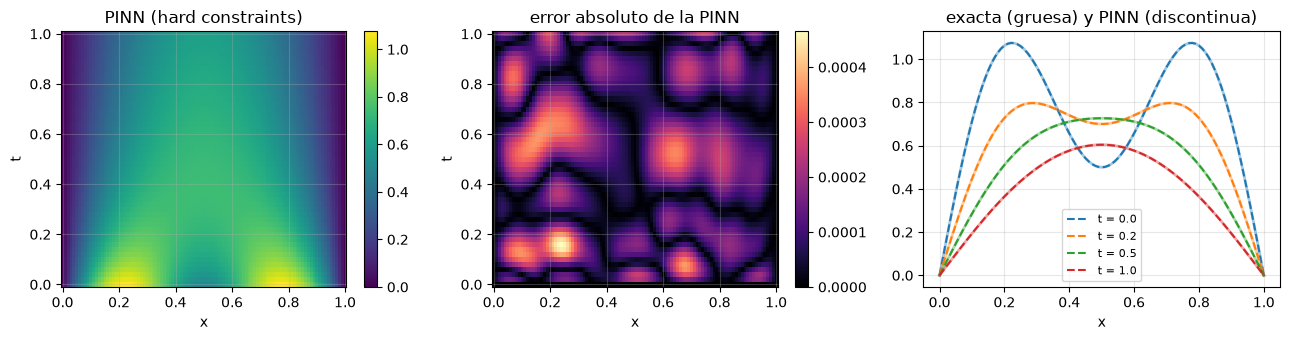

In [5]:
XG, TG = np.meshgrid(np.linspace(0, 1, 101), np.linspace(0, 1, 51))     # malla de evaluación (t a lo largo de las filas)
U_EXACT = heat_exact(XG, TG)

def heat_terms(f, P, tb, xi):
    # término del residuo y término de las condiciones de la pérdida de la ecuación del calor para un modelo f(x, t) -> u
    xt_ = P.clone().requires_grad_(True)                                  # columnas: x, t
    u = f(xt_); g = d(u, xt_)
    u_xx = d(g[:, 0:1], xt_)[:, 0:1]
    L_r = ((g[:, 1:2] - NU * u_xx) ** 2).mean()
    u_l = f(torch.cat([torch.zeros_like(tb), tb], 1)); u_r = f(torch.cat([torch.ones_like(tb), tb], 1))
    u_i = f(torch.cat([xi, torch.zeros_like(xi)], 1))
    u0v = torch.sin(math.pi * xi) + 0.5 * torch.sin(3 * math.pi * xi)
    L_b = (u_l ** 2).mean() + (u_r ** 2).mean() + ((u_i - u0v) ** 2).mean()
    return L_r, L_b

def train_heat(seed, w=1.0, adaptive=False, hard=False, steps=2000, lbfgs_iter=300, width=32, n_c=1000):
    # hard=True incorpora ambas condiciones al modelo: u = u0(x) + t x (1 - x) N(x, t) vale exactamente u0 en t = 0 y 0 en x = 0, 1
    torch.manual_seed(seed)
    net = mlp([2, width, width, width, 1]); params = list(net.parameters())
    if hard:
        f = lambda xt_: (torch.sin(math.pi * xt_[:, 0:1]) + 0.5 * torch.sin(3 * math.pi * xt_[:, 0:1])) + xt_[:, 1:2] * xt_[:, 0:1] * (1 - xt_[:, 0:1]) * net(xt_)
    else:
        f = net
    P = torch.rand(n_c, 2); tb = torch.rand(100, 1); xi = torch.rand(200, 1)        # puntos de entrenamiento fijos para la etapa L-BFGS
    opt = torch.optim.Adam(params, lr=2e-3)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / steps))
    lam = w; t_start = time.perf_counter(); lam_hist = []
    for s in range(steps):                                                           # etapa 1: Adam con puntos aleatorios nuevos
        opt.zero_grad()
        L_r, L_b = heat_terms(f, torch.rand(n_c, 2), torch.rand(100, 1), torch.rand(200, 1))
        if adaptive and s % 50 == 0:
            # recocido de la tasa de aprendizaje de Wang et al.: escalar el término de las condiciones para que su gradiente absoluto medio iguale al del residuo
            g_r = torch.autograd.grad(L_r, params, retain_graph=True, allow_unused=True)
            g_b = torch.autograd.grad(L_b, params, retain_graph=True, allow_unused=True)
            mean_r = float(torch.cat([g.flatten().abs() for g in g_r if g is not None]).mean())
            mean_b = float(torch.cat([g.flatten().abs() for g in g_b if g is not None]).mean())
            lam = 0.9 * lam + 0.1 * mean_r / (mean_b + 1e-12)
        lam_hist.append(lam)
        (L_r + lam * L_b).backward(); opt.step(); sched.step()
    lbfgs = torch.optim.LBFGS(params, lr=1, max_iter=lbfgs_iter, history_size=50, line_search_fn="strong_wolfe")
    def closure():                                                                   # etapa 2: L-BFGS sobre los puntos fijos, lambda congelado
        lbfgs.zero_grad(); L_r, L_b = heat_terms(f, P, tb, xi); l = L_r + lam * L_b; l.backward(); return l
    lbfgs.step(closure)
    sec = time.perf_counter() - t_start
    with torch.no_grad():
        pred = f(torch.tensor(np.stack([XG.ravel(), TG.ravel()], 1), dtype=torch.float32)).numpy().reshape(XG.shape)
    return pred, sec, lam_hist

heat_runs = {}
variants = [("lambda = 0.01", dict(w=0.01)), ("lambda = 1", dict(w=1.0)), ("lambda = 100", dict(w=100.0)), ("hard constraints", dict(hard=True))]
for name, kw in variants:
    errs = []
    for seed in range(2):
        pred, sec, _ = train_heat(seed, **kw)
        heat_runs[(name, seed)] = pred; errs.append(rel_l2(pred, U_EXACT))
    print(f"{name:17s}: error L2 relativo por semilla {errs[0]:.2e}, {errs[1]:.2e}   ({sec:.1f} s por ejecución)")
best_name = min([v[0] for v in variants], key=lambda n: rel_l2(heat_runs[(n, 0)], U_EXACT))
pred_best = heat_runs[(best_name, 0)]; PINN_SEC = sec

# el solver de diferencias finitas sobre la misma malla de evaluación
for nx, nt in [(20, 20), (100, 100)]:
    (xg, ug, hist), fd_sec = timed(lambda: heat_fd(nx, nt, keep=True), reps=10)
    interp = RegularGridInterpolator((np.linspace(0, 1, nt + 1), xg), hist)
    fd_pred = interp(np.stack([TG.ravel(), XG.ravel()], 1)).reshape(XG.shape)
    print(f"diferencias finitas {nx}x{nt}: error L2 relativo {rel_l2(fd_pred, U_EXACT):.2e}, {fd_sec*1e3:.2f} ms")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
im = ax[0].pcolormesh(XG, TG, pred_best, shading="auto", cmap="viridis"); ax[0].set_title(f"PINN ({best_name})"); plt.colorbar(im, ax=ax[0])
im = ax[1].pcolormesh(XG, TG, np.abs(pred_best - U_EXACT), shading="auto", cmap="magma"); ax[1].set_title("error absoluto de la PINN"); plt.colorbar(im, ax=ax[1])
for ti, c in zip([0, 10, 25, 50], ["C0", "C1", "C2", "C3"]):
    ax[2].plot(XG[0], U_EXACT[ti], c, lw=2, alpha=0.4); ax[2].plot(XG[0], pred_best[ti], c + "--", label=f"t = {TG[ti,0]:.1f}")
ax[2].set_title("exacta (gruesa) y PINN (discontinua)"); ax[2].legend(fontsize=8)
for a in ax[:2]: a.set_xlabel("x"); a.set_ylabel("t")
ax[2].set_xlabel("x"); plt.tight_layout(); plt.show()

**Lectura.** La ponderación importa mucho. Con un $\lambda=0.01$ muy pequeño las condiciones se ignoran y el error es de 15 % a 16 %; $\lambda=1$ dio 0.7 % y 5 %, y $\lambda=100$ dio 3.4 % y 0.9 %: ningún valor fijo fue el mejor para las dos semillas. La versión con **restricción dura** no tenía peso que ajustar y fue mejor en uno a dos órdenes de magnitud, 2.6e-4 y 3.1e-4 en las dos semillas, porque las condiciones se cumplen exactamente y el optimizador solo debe resolver el residuo. Eso es posible aquí solo porque el perfil inicial es una fórmula conocida y el dominio es un rectángulo. Frente al solver clásico la comparación es aleccionadora: una malla de diferencias finitas de 20 por 20 celdas tiene un error de 3.6e-3 en 0.45 ms y una de 100 por 100 tiene 8.5e-5 en unos 2 ms, mientras que la mejor PINN necesita de 12 a 14 s para 2.6e-4. La PINN es miles de veces más lenta y aun así menos precisa que el solver de 100 por 100. Su atractivo está en otra parte: no necesita malla, es derivable y puede incorporar mediciones, como en las secciones siguientes.

## 5. El problema inverso: identificar un parámetro a partir de datos ruidosos

En el **problema inverso** la ecuación se conoce pero un coeficiente no: aquí, el coeficiente de difusión $\nu$ de la barra. Disponemos de **300 mediciones ruidosas** $u(x_i,t_i)$ en puntos aleatorios del dominio espacio-temporal, con desviación típica del ruido $\sigma\in\{0,0.02,0.1,0.2\}$ (la temperatura es de orden 1, así que $\sigma=0.2$ es grande). No damos el perfil inicial, que también es desconocido.

* **PINN.** Una red del mismo tipo que antes (Adam y luego L-BFGS), con $\log\nu$ como parámetro entrenable adicional (partiendo del valor erróneo $\nu=0.2$), y la pérdida error cuadrático medio de los datos + 10 veces el residuo de la EDP + condición de contorno (el peso 10 del residuo se eligió tras una pequeña prueba; sin él las estimaciones fueron parecidas o peores). La física rellena el espacio entre las mediciones.
* **Ajuste clásico.** Mínimos cuadrados no lineales (`scipy.optimize.least_squares`) sobre $\nu$ y un perfil inicial desconocido escrito como suma de cuatro senos, $u_0=\sum_{k=1}^4 c_k\sin(k\pi x)$ (5 incógnitas), donde cada candidato se evalúa con nuestro solver de Crank-Nicolson (64 por 64 celdas). Conoce la misma física y conoce la *forma* del perfil, lo cual es un favor que se le hace.

Repetimos cada nivel de ruido con 3 conjuntos aleatorios de mediciones y damos el error absoluto medio de $\nu$ en porcentaje.

nu verdadero = 0.05.  error absoluto medio del nu identificado, en porcentaje (3 repeticiones cada uno)
 ruido sigma         PINN     MC clásico   nu identificado por repetición (PINN | clásico)
         0.0        39.4%           0.1%   0.0135 0.0283 0.0491 | 0.0500 0.0500 0.0500
        0.02        39.9%           0.5%   0.0170 0.0280 0.0451 | 0.0504 0.0500 0.0497
         0.1        43.3%           2.3%   0.0226 0.0296 0.0328 | 0.0520 0.0501 0.0486
         0.2        45.7%           4.6%   0.0279 0.0264 0.0271 | 0.0540 0.0503 0.0473
tiempo por identificación: PINN 12.0 s, mínimos cuadrados clásicos 0.07 s


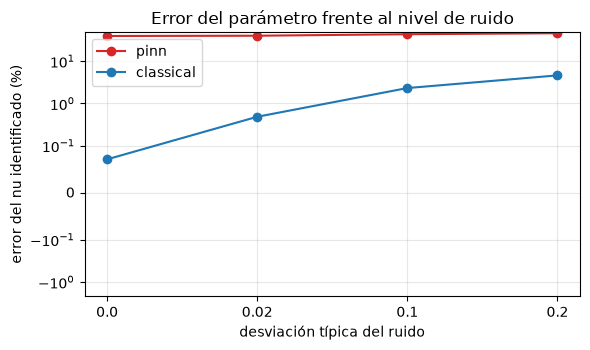

In [6]:
def make_obs(sigma, seed, n=300):
    r_ = np.random.default_rng(seed)
    x = r_.uniform(0, 1, n); t = r_.uniform(0, 1, n)
    return x, t, heat_exact(x, t) + sigma * r_.normal(size=n)

def pinn_inverse(xo, to, uo, seed, steps=2000, nu_init=0.2, lbfgs_iter=300):
    torch.manual_seed(seed)
    net = mlp([2, 32, 32, 32, 1]); log_nu = nn.Parameter(torch.tensor(math.log(nu_init)))
    params = list(net.parameters()) + [log_nu]
    xyo = torch.tensor(np.stack([xo, to], 1), dtype=torch.float32); uo_t = torch.tensor(uo, dtype=torch.float32).reshape(-1, 1)
    def loss_fn(P, tb):
        xt_ = P.clone().requires_grad_(True)
        u = net(xt_); g = d(u, xt_); u_xx = d(g[:, 0:1], xt_)[:, 0:1]
        L_r = ((g[:, 1:2] - torch.exp(log_nu) * u_xx) ** 2).mean()
        L_b = (net(torch.cat([torch.zeros_like(tb), tb], 1)) ** 2).mean() + (net(torch.cat([torch.ones_like(tb), tb], 1)) ** 2).mean()
        return ((net(xyo) - uo_t) ** 2).mean() + 10 * L_r + L_b
    opt = torch.optim.Adam([{"params": list(net.parameters()), "lr": 2e-3}, {"params": [log_nu], "lr": 1e-2}])
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / steps))
    for s in range(steps):
        opt.zero_grad(); loss_fn(torch.rand(1000, 2), torch.rand(100, 1)).backward(); opt.step(); sched.step()
    P = torch.rand(1000, 2); tb = torch.rand(100, 1)
    lbfgs = torch.optim.LBFGS(params, lr=1, max_iter=lbfgs_iter, history_size=50, line_search_fn="strong_wolfe")
    def closure():
        lbfgs.zero_grad(); l = loss_fn(P, tb); l.backward(); return l
    lbfgs.step(closure)
    return float(torch.exp(log_nu))

def classical_inverse(xo, to, uo, n=64):
    # incógnitas: nu y los cuatro coeficientes seno del perfil inicial desconocido
    def model(theta):
        nu, c = theta[0], theta[1:]
        u0 = lambda x: sum(ck * np.sin((k + 1) * np.pi * x) for k, ck in enumerate(c))
        xg, _, hist = heat_fd(n, n, nu=nu, u0=u0, keep=True)
        return RegularGridInterpolator((np.linspace(0, 1, n + 1), xg), hist)(np.stack([to, xo], 1))
    sol = least_squares(lambda th: model(th) - uo, x0=[0.2, 0.5, 0.0, 0.0, 0.0], bounds=([1e-4, -5, -5, -5, -5], [2, 5, 5, 5, 5]))
    return sol.x[0]

sigmas = [0.0, 0.02, 0.1, 0.2]
inv = {s: {"pinn": [], "classical": []} for s in sigmas}
t_pinn = t_cls = 0.0
for sigma in sigmas:
    for seed in range(3):
        xo, to, uo = make_obs(sigma, 500 + seed)
        t1 = time.perf_counter(); inv[sigma]["pinn"].append(pinn_inverse(xo, to, uo, seed)); t_pinn += time.perf_counter() - t1
        t1 = time.perf_counter(); inv[sigma]["classical"].append(classical_inverse(xo, to, uo)); t_cls += time.perf_counter() - t1
print(f"nu verdadero = {NU}.  error absoluto medio del nu identificado, en porcentaje (3 repeticiones cada uno)")
print(f"{'ruido sigma':>12} {'PINN':>12} {'MC clásico':>14}   nu identificado por repetición (PINN | clásico)")
for sigma in sigmas:
    ep = [100 * abs(v - NU) / NU for v in inv[sigma]["pinn"]]; ec = [100 * abs(v - NU) / NU for v in inv[sigma]["classical"]]
    print(f"{sigma:>12} {np.mean(ep):>11.1f}% {np.mean(ec):>13.1f}%   " + " ".join(f"{v:.4f}" for v in inv[sigma]["pinn"]) + " | " + " ".join(f"{v:.4f}" for v in inv[sigma]["classical"]))
print(f"tiempo por identificación: PINN {t_pinn/12:.1f} s, mínimos cuadrados clásicos {t_cls/12:.2f} s")

fig, ax = plt.subplots(figsize=(6, 3.6))
for key, c in [("pinn", "tab:red"), ("classical", "tab:blue")]:
    m = [np.mean([100 * abs(v - NU) / NU for v in inv[s][key]]) for s in sigmas]
    ax.plot(range(len(sigmas)), m, "o-", color=c, label=key)
ax.set_xticks(range(len(sigmas))); ax.set_xticklabels([str(s) for s in sigmas]); ax.set_yscale("symlog", linthresh=0.1)
ax.set_xlabel("desviación típica del ruido"); ax.set_ylabel("error del nu identificado (%)"); ax.legend(); ax.set_title("Error del parámetro frente al nivel de ruido")
plt.tight_layout(); plt.show()

**Lectura.** El resultado es un claro negativo para la PINN en este contexto. Los mínimos cuadrados clásicos recuperaron $\nu$ con 0.1 % sin ruido, y su error creció con el ruido como debe (0.5 %, 2.3 % y 4.6 % para $\sigma=0.02$, 0.1 y 0.2), en 0.07 s por ajuste. El error de la PINN fue de 39 % a 46 % en todos los niveles de ruido, con estimaciones entre 0.014 y 0.049 para un valor verdadero de 0.05, casi siempre demasiado bajas, y cada ajuste tardó 12 s. Como el error de la PINN no crece con el ruido, no es un efecto del ruido: es un sesgo de optimización de nuestro pequeño presupuesto (2,000 pasos de Adam y 300 iteraciones de L-BFGS para una red de 32 unidades). Una explicación plausible, no comprobada, es que una red mal ajustada tiene una segunda derivada irregular y la pérdida del residuo puede reducirse encogiendo $\nu$. Probamos una ejecución más larga, un peso mayor del residuo, un calentamiento solo con datos y dar el perfil inicial, y las estimaciones siguieron sesgadas a la baja, así que no afirmamos que sea fácil de arreglar. Las identificaciones con PINN publicadas tienen éxito con presupuestos mayores y problemas ajustados, pero esta es la experiencia de una primera implementación. La regla práctica es que **cuando tienes un solver y un modelo correcto, ajusta con el solver**; usa una PINN cuando no lo tienes, cuando el modelo es incómodo de derivar o cuando necesitas el parámetro dentro de una red mayor, y comprueba entonces la identificación con un conjunto de mediciones reservado.

## 6. Cuándo fallan las PINN y los remedios

Las PINN tienen fama de ser fáciles de escribir y difíciles de entrenar. Tres modos de fallo explican la mayor parte de los problemas; mostramos cada uno con una medición y probamos el remedio estándar.

### 6.1 Sesgo espectral y rasgos de Fourier

Las redes neuronales aprenden primero las frecuencias bajas (**sesgo espectral**). Pedimos a una red que resuelva la EDO trivial $\dot u=\omega\cos(\omega t)$, $u(0)=0$ en $[0,2\pi]$ (solución exacta $u=\sin\omega t$, con $\omega$ la frecuencia angular del objetivo; la condición inicial se impone como restricción dura $u=t\,N(t)$) y aumentamos $\omega$. El remedio de Tancik et al. (2020) son los **rasgos de Fourier**: se alimenta la red con $[t,\sin(Bt),\cos(Bt)]$, con un vector aleatorio fijo $B$ de 32 frecuencias extraídas de una distribución normal de desviación típica $\sigma_F$ (sigma F), de modo que las frecuencias altas están disponibles desde el principio. La escala $\sigma_F$ es un hiperparámetro, y una mala escala perjudica, así que barremos $\sigma_F\in\{2,5,10\}$ ($\sigma_F=0$ es la red simple).

error L2 relativo de la solución PINN de u' = omega cos(omega t) (1 semilla); sigma_F = 0 es el MLP simple
 omega    sigma_F = 0    sigma_F = 2    sigma_F = 5   sigma_F = 10


     1       6.23e-03       7.20e-04       8.03e-03       2.69e-01


     4       1.62e-02       8.00e-04       2.06e-02       3.10e-01


    10       9.64e-01       4.95e-02       1.29e-01       5.67e-01


    20       1.01e+00       2.72e-01       4.71e-01       5.62e-01


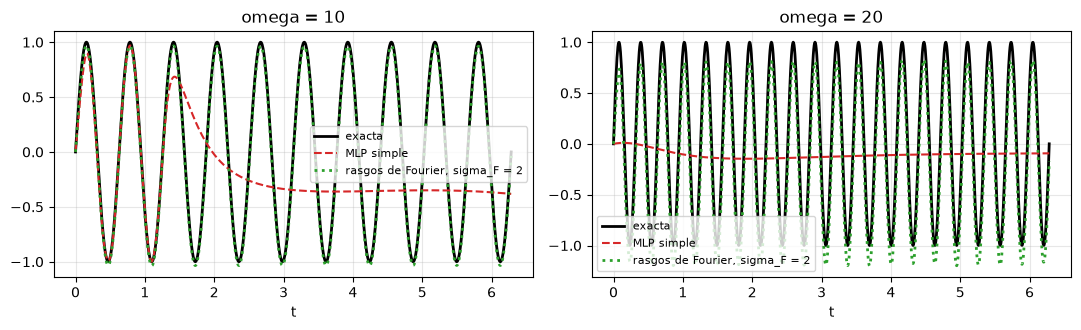

In [7]:
def train_freq(omega, sigma_f, seed=0, steps=2000):
    # sigma_f = 0 es un MLP simple; si no, la entrada es [t, sin(Bt), cos(Bt)] con 32 frecuencias aleatorias B ~ N(0, sigma_f^2)
    torch.manual_seed(seed)
    B = torch.randn(32) * sigma_f
    feat = (lambda t: torch.cat([t, torch.sin(t * B), torch.cos(t * B)], 1)) if sigma_f else (lambda t: t)
    net = mlp([65 if sigma_f else 1, 64, 64, 64, 1])
    u = lambda t: t * net(feat(t))                                  # restricción dura u(0) = 0
    opt = torch.optim.Adam(net.parameters(), lr=2e-3)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / steps))
    for s in range(steps):
        opt.zero_grad()
        t = (torch.rand(512, 1) * 2 * math.pi).requires_grad_(True)
        loss = ((d(u(t), t) - omega * torch.cos(omega * t)) ** 2).mean()
        loss.backward(); opt.step(); sched.step()
    tg = torch.linspace(0, 2 * math.pi, 1000).reshape(-1, 1)
    with torch.no_grad(): pred = u(tg).numpy().ravel()
    return tg.numpy().ravel(), pred

omegas = [1, 4, 10, 20]; sigmas_f = [0, 2, 5, 10]
freq_res = {}
print("error L2 relativo de la solución PINN de u' = omega cos(omega t) (1 semilla); sigma_F = 0 es el MLP simple")
print(f"{'omega':>6} " + " ".join(f"{'sigma_F = ' + str(sf):>14}" for sf in sigmas_f))
for om in omegas:
    row = []
    for sf in sigmas_f:
        tg, pred = train_freq(om, sf); freq_res[(om, sf)] = pred; row.append(rel_l2(pred, np.sin(om * tg)))
    print(f"{om:>6} " + " ".join(f"{e:>14.2e}" for e in row))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, om in zip(ax, [10, 20]):
    a.plot(tg, np.sin(om * tg), "k", lw=2, label="exacta"); a.plot(tg, freq_res[(om, 0)], "--", color="tab:red", label="MLP simple")
    a.plot(tg, freq_res[(om, 2)], ":", color="tab:green", lw=2, label="rasgos de Fourier, sigma_F = 2"); a.set_title(f"omega = {om}"); a.set_xlabel("t"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.** El sesgo espectral es visible y fuerte: la red simple resuelve $\omega=1$ y $\omega=4$ (errores de 0.6 % y 1.6 %) y falla por completo con $\omega=10$ y 20 (errores de 0.96 y 1.0, devuelve algo suave que no tiene nada que ver con el objetivo). Con rasgos de Fourier y $\sigma_F=2$ el error baja a 0.07 % y 0.08 % en baja frecuencia, 5 % con $\omega=10$ y 27 % con $\omega=20$, una gran mejora que aun así no resuelve $\omega=20$. La escala importa: $\sigma_F=5$ es peor en todas las frecuencias que $\sigma_F=2$, y $\sigma_F=10$ es peor que la red simple con $\omega=1$ y 4 (27 % y 31 %), porque frecuencias altas aleatorias ajustan ruido entre los puntos de colocación. El remedio funciona solo cuando la escala de los rasgos está ajustada al objetivo, lo cual significa saber algo de la solución de antemano. Una semilla por celda.

### 6.2 Desequilibrio de la pérdida y pesos adaptativos

La sección 4 mostró que el peso $\lambda$ de las condiciones frente a la ecuación cambia el resultado y hay que ajustarlo. La **ponderación adaptativa** (el recocido de la tasa de aprendizaje de Wang, Teng y Perdikaris, 2021) elimina ese hiperparámetro: cada 50 pasos fija $\lambda$ de modo que el gradiente absoluto medio del término de las condiciones iguale al del término del residuo (Wang et al. usan el mayor gradiente del residuo; la media es una variante más simple que fue más estable en nuestras pruebas, donde el máximo llevó $\lambda$ por encima de 1,000). La celda siguiente repite la PINN del calor con esta regla, partiendo de $\lambda=1$, y la compara con los pesos fijos de la sección 4.

PINN de la ecuación del calor, error L2 relativo (2 semillas)
  lambda = 0.01    : 1.52e-01, 1.63e-01
  lambda = 1       : 7.49e-03, 5.02e-02
  lambda = 100     : 3.43e-02, 9.18e-03
  hard constraints : 2.56e-04, 3.11e-04
  lambda adaptativo: 7.61e-03, 1.09e-01   (lambda al final: 0.3, 0.1)


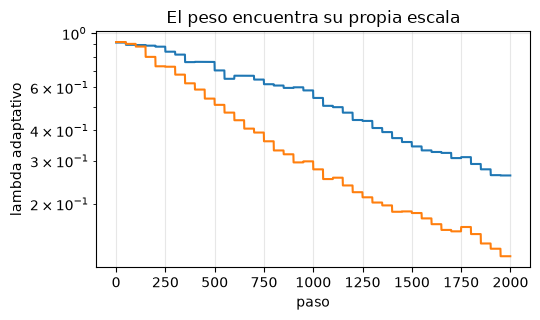

In [8]:
ad_errs, ad_lams = [], []
for seed in range(2):
    pred, sec, lam_hist = train_heat(seed, adaptive=True)
    ad_errs.append(rel_l2(pred, U_EXACT)); ad_lams.append(lam_hist)
print("PINN de la ecuación del calor, error L2 relativo (2 semillas)")
for name, _ in variants:
    print(f"  {name:17s}: " + ", ".join(f"{rel_l2(heat_runs[(name, s)], U_EXACT):.2e}" for s in range(2)))
print("  lambda adaptativo: " + ", ".join(f"{e:.2e}" for e in ad_errs) + f"   (lambda al final: {ad_lams[0][-1]:.1f}, {ad_lams[1][-1]:.1f})")
fig, ax = plt.subplots(figsize=(5.5, 3.3))
for h in ad_lams: ax.semilogy(h)
ax.set_xlabel("paso"); ax.set_ylabel("lambda adaptativo"); ax.set_title("El peso encuentra su propia escala"); plt.tight_layout(); plt.show()

**Lectura.** La regla adaptativa encontró por sí sola una escala utilizable: partiendo de $\lambda=1$ se estabilizó en $\lambda=0.3$ y 0.1 y los errores fueron 0.8 % y 11 %. Frente a los pesos fijos de la sección 4 esto es tan bueno como el mejor valor fijo en la semilla 0 y peor que $\lambda=1$ en la semilla 1 (5 %), de modo que el beneficio es **no tener que adivinar la escala** (la mala suposición $\lambda=0.01$ dio 15 %), no una precisión mayor que la de un peso bien elegido. La versión del artículo original, que usa el mayor gradiente del residuo, hizo crecer $\lambda$ hasta los miles en nuestras primeras pruebas y dio peores errores, así que la variante que usamos es una simplificación deliberada. Con dos semillas, la diferencia entre el peso adaptativo y el mejor peso fijo cabe dentro de la variación entre semillas, y no afirmamos ninguna ventaja. La restricción dura de la sección 4 (2.6e-4) supera a cualquier esquema de ponderación cuando está disponible.

### 6.3 Problemas rígidos, horizontes largos, entrenamiento causal y rasgos de Fourier en el tiempo

Krishnapriyan et al. (2021) muestran que las PINN fallan en problemas que parecen inocentes. Su ejemplo estándar es la **ecuación de convección** $u_t+\beta u_x=0$ en el dominio periódico $x\in[0,2\pi]$ con $u(x,0)=\sin x$, donde $\beta$ (beta) es la velocidad de la onda. La solución es solo un seno que viaja, $u=\sin(x-\beta t)$, pero al crecer $\beta$ la red debe representar más oscilaciones en $t\in[0,1]$ y el residuo se convierte en un paisaje de pérdida muy rígido y multiescala.

Probamos tres versiones de la misma red con el mismo presupuesto (Adam y luego L-BFGS), para $\beta\in\{1,10,30\}$:

* **simple**: el residuo se promedia sobre todos los tiempos;
* **entrenamiento causal** (Wang, Sankaran y Perdikaris, 2022), que respeta la flecha del tiempo: se divide $[0,1]$ en $M=16$ intervalos con pérdidas medias del residuo $\mathcal L_i$ y se pondera el intervalo $i$ con $w_i=\exp\!\big(-\varepsilon\sum_{k<i}\mathcal L_k\big)$ (con $\varepsilon$, épsilon, una constante positiva, aquí 1; los pesos se tratan como constantes en el gradiente). Un intervalo solo cuenta cuando todos los anteriores tienen un residuo pequeño. Se diseñó para horizontes temporales largos, donde una red puede bajar la pérdida en tiempos tardíos mientras los tempranos siguen mal;
* **rasgos de Fourier en $t$**: la pérdida simple pero con la entrada $[\sin x,\cos x,t,\sin(Bt),\cos(Bt)]$ donde $B$ tiene 16 frecuencias aleatorias de desviación típica $0.3\beta$. La rigidez es, en buena parte, sesgo espectral a lo largo del eje temporal, así que el remedio de la sección 6.1 debería aplicarse; la escala es de nuevo una elección que hicimos conociendo $\beta$.

Las tres usan el mismo muestreo de 64 puntos por intervalo de tiempo, y damos una semilla (esta sección es la más cara).

error L2 relativo en todo el dominio espacio-temporal (1 semilla), Adam 3000 pasos y luego L-BFGS
 beta     simple     causal  Fourier en t


    1   6.98e-04        nan           nan


   10   2.64e-01   1.85e-01      1.06e-02


   30   9.35e-01   9.36e-01      5.35e-01
(144 s en total)


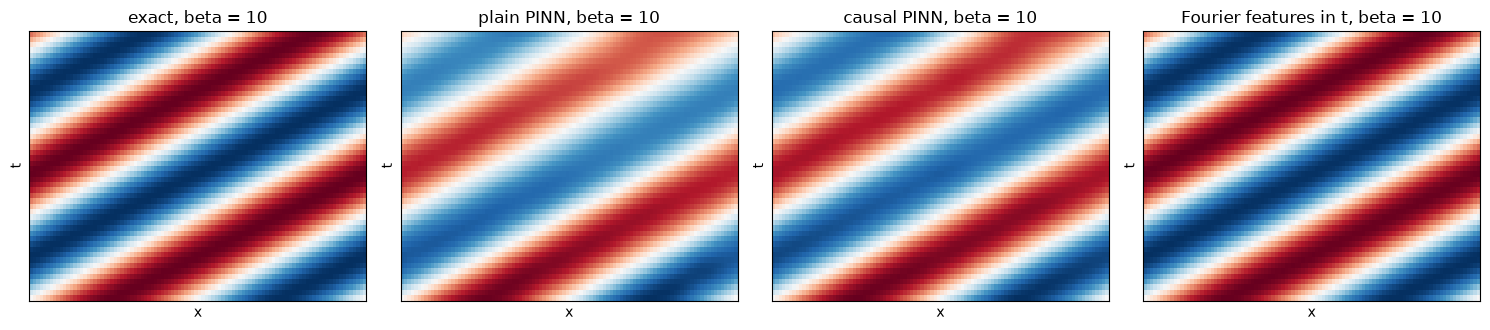

In [9]:
def train_conv(beta, mode, seed=0, steps=3000, lbfgs_iter=300, eps=1.0, M=16, k=64):
    # mode: "plain", "causal" (pesos ordenados en el tiempo) o "fourier" (pérdida simple, rasgos de Fourier de t con escala 0.3 beta)
    torch.manual_seed(seed)
    B = torch.randn(16) * 0.3 * beta
    def feats(x, t):
        z = [torch.sin(x), torch.cos(x), t]                              # sin x, cos x hacen la red periódica en x
        if mode == "fourier": z += [torch.sin(t * B), torch.cos(t * B)]
        return torch.cat(z, 1)
    net = mlp([35 if mode == "fourier" else 3, 64, 64, 64, 1]); f = lambda x, t: net(feats(x, t))
    bins = torch.arange(M).reshape(M, 1).float()
    def loss_fn(t, x, xi):
        t = t.clone().requires_grad_(True); x = x.clone().requires_grad_(True)
        u = f(x, t)
        L_i = (((d(u, t) + beta * d(u, x)) / beta) ** 2).reshape(M, k).mean(1)   # residuo por intervalo de tiempo (dividido por beta para conservar la escala)
        w = torch.exp(-eps * (torch.cumsum(L_i, 0) - L_i)).detach() if mode == "causal" else torch.ones(M)   # solo los intervalos anteriores
        L_ic = ((f(xi, torch.zeros_like(xi)) - torch.sin(xi)) ** 2).mean()
        return (w * L_i).mean() + L_ic
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / steps))
    for s in range(steps):
        opt.zero_grad()
        loss_fn((bins + torch.rand(M, k)).div(M).reshape(-1, 1), torch.rand(M * k, 1) * 2 * math.pi, torch.rand(200, 1) * 2 * math.pi).backward()
        opt.step(); sched.step()
    tf = (bins + torch.rand(M, k)).div(M).reshape(-1, 1); xf = torch.rand(M * k, 1) * 2 * math.pi; xif = torch.rand(200, 1) * 2 * math.pi
    lbfgs = torch.optim.LBFGS(net.parameters(), lr=1, max_iter=lbfgs_iter, history_size=50, line_search_fn="strong_wolfe")
    def closure():
        lbfgs.zero_grad(); l = loss_fn(tf, xf, xif); l.backward(); return l
    lbfgs.step(closure)
    xg_, tg_ = np.meshgrid(np.linspace(0, 2 * np.pi, 100), np.linspace(0, 1, 50))
    with torch.no_grad():
        pred = f(torch.tensor(xg_.ravel(), dtype=torch.float32).reshape(-1, 1), torch.tensor(tg_.ravel(), dtype=torch.float32).reshape(-1, 1)).numpy().reshape(xg_.shape)
    return pred, np.sin(xg_ - beta * tg_)

conv = {}; t_conv = time.perf_counter()
print("error L2 relativo en todo el dominio espacio-temporal (1 semilla), Adam 3000 pasos y luego L-BFGS")
print(f"{'beta':>5} {'simple':>10} {'causal':>10} {'Fourier en t':>13}")
for beta in [1, 10, 30]:
    row = []
    for mode in ["plain", "causal", "fourier"]:
        if beta == 1 and mode != "plain":
            row.append(float("nan")); continue
        pred, true = train_conv(beta, mode); conv[(beta, mode)] = pred; row.append(rel_l2(pred, true))
    print(f"{beta:>5} {row[0]:>10.2e} {row[1]:>10.2e} {row[2]:>13.2e}")
print(f"({time.perf_counter() - t_conv:.0f} s en total)")
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
xg_, tg_ = np.meshgrid(np.linspace(0, 2 * np.pi, 100), np.linspace(0, 1, 50))
panels = [("exact, beta = 10", np.sin(xg_ - 10 * tg_)), ("plain PINN", conv[(10, "plain")]), ("causal PINN", conv[(10, "causal")]), ("Fourier features in t", conv[(10, "fourier")])]
for a, (name, z) in zip(ax, panels):
    a.pcolormesh(z, cmap="RdBu_r", vmin=-1, vmax=1); a.set_title(name + ("" if name.startswith("exact") else ", beta = 10")); a.set_xlabel("x"); a.set_ylabel("t"); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Lectura.** Para el caso suave $\beta=1$ la PINN simple es precisa (7e-4). Con $\beta=10$ la PINN simple falla (error relativo 0.26) y con $\beta=30$ no tiene ninguna habilidad (0.94, la función equivocada en todas partes): el fallo por rigidez de Krishnapriyan et al. reproducido en un entorno pequeño. **El entrenamiento causal no lo rescató**: 0.19 con $\beta=10$ (una mejora modesta que una sola semilla no puede confirmar) y ningún cambio con $\beta=30$. También probamos otros valores de $\varepsilon$ y vimos que los grandes detienen por completo el entrenamiento de los tiempos tardíos; esto no es una refutación del método, cuyas mejoras publicadas son para problemas caóticos y turbulentos de tiempo largo, pero muestra que no es un remedio general y que nuestro problema está limitado por el contenido en frecuencia en el tiempo, no por el orden de los sucesos. El remedio que sí funcionó es el de la sección 6.1: los **rasgos de Fourier en $t$** llevaron $\beta=10$ de 0.26 a 0.011, una mejora de 25 veces, y redujeron a la mitad el error con $\beta=30$ (0.54) sin resolverlo. Nota que la escala de los rasgos (0.3 $\beta$) usó nuestro conocimiento de $\beta$, como en la sección 6.1. Una semilla por celda, así que diferencias de un factor dos no son fiables, pero la mejora de 25 veces y el orden simple frente a Fourier con $\beta=10$ van mucho más allá de lo que el ruido de semilla puede explicar.

## 7. Operadores neuronales: aprender la aplicación solución

Una PINN resuelve **una** instancia: si cambias la condición inicial, reentrenas. Muchas aplicaciones necesitan la respuesta para **miles de entradas distintas**. Un **operador neuronal** aprende el **operador solución** $\mathcal G$ (G caligráfica), la aplicación de una función de entrada a la función solución, por ejemplo de la condición inicial $u_0(x)$ a la solución en un instante posterior, $u(\cdot,T)=\mathcal G(u_0)$. Se entrena con pares producidos por un solver clásico, de modo que no necesita la ecuación, y una vez entrenado una instancia nueva cuesta una pasada hacia delante.

Nuestro caso de prueba es la **ecuación de Burgers viscosa**, un fluido unidimensional con un término no lineal que empina las ondas hasta formar choques y una viscosidad que los suaviza:

$$u_t+u\,u_x=\nu\,u_{xx},\qquad x\in[0,1)\text{ periódico},\quad \nu=0.02,\quad T=1.$$

Escribimos el solver nosotros mismos: un método **pseudoespectral** (derivadas mediante la transformada rápida de Fourier, FFT) con la exponencial exacta para el término viscoso y un paso de Runge-Kutta de cuarto orden para el no lineal (el esquema de factor integrante), la regla de 2/3 para eliminar el aliasing, 128 puntos de malla y 500 pasos de tiempo. Las condiciones iniciales son funciones suaves aleatorias, $u_0(x)=\sum_{m=1}^{M}\big(a_m\cos 2\pi mx+b_m\sin 2\pi mx\big)$ con $a_m,b_m\sim\mathcal N(0,s_m^2)$, $s_m=0.6/(1+m)$ y $M=12$ modos (dentro de la distribución). Comprobamos el solver con una malla más fina y con el paso de tiempo a la mitad antes de usarlo como verdad de referencia.

comprobación del solver: paso de tiempo a la mitad -> diferencia relativa 3.8e-09; 256 en lugar de 128 puntos -> 5.8e-15


generados 1000 pares de entrenamiento en 1.5 s con el solver (por lotes, 128 puntos); malla de entrenamiento de 64 puntos
distancia L2 relativa entre u(T) y u(0) (la referencia de 'no hacer nada'): 0.88


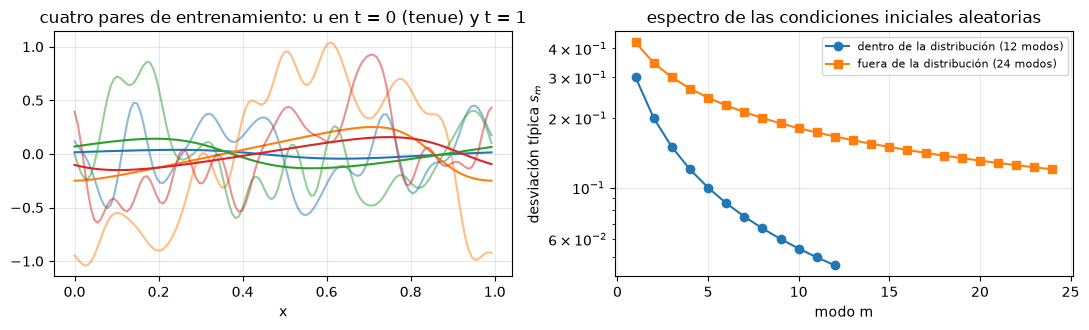

In [10]:
NU_B, T_B = 0.02, 1.0

def burgers_solve(u0, nu=NU_B, T=T_B, dt=2e-3):
    # u0: (lote, N) en la malla periódica x_j = j/N. RK4 con factor integrante, pseudoespectral, dealiasing 2/3
    B, N = u0.shape
    k = np.fft.rfftfreq(N, 1.0 / N) * 2 * np.pi
    E = np.exp(-nu * k**2 * dt / 2); E2 = E * E
    mask = np.arange(len(k)) <= N // 3
    nl = lambda v: -1j * k * np.fft.rfft(0.5 * np.fft.irfft(v, n=N) ** 2) * mask       # -(u^2/2)_x en el espacio de Fourier
    v = np.fft.rfft(u0)
    for _ in range(int(round(T / dt))):
        k1 = nl(v); k2 = nl(E * (v + dt / 2 * k1)); k3 = nl(E * v + dt / 2 * k2); k4 = nl(E2 * v + dt * E * k3)
        v = E2 * v + dt / 6 * (E2 * k1 + 2 * E * (k2 + k3) + k4)
    return np.fft.irfft(v, n=N)

def sample_ic(n, M, amp, p, rng):
    m = np.arange(1, M + 1); s = amp / (1 + m) ** p
    return rng.normal(size=(n, M)) * s, rng.normal(size=(n, M)) * s

def eval_ic(a, b, N):
    x = np.arange(N) / N; m = np.arange(1, a.shape[1] + 1)
    return a @ np.cos(2 * np.pi * np.outer(m, x)) + b @ np.sin(2 * np.pi * np.outer(m, x))

rng = np.random.default_rng(0)
A_tr, B_tr = sample_ic(1000, 12, 0.6, 1.0, rng)          # condiciones iniciales de entrenamiento
A_te, B_te = sample_ic(100, 12, 0.6, 1.0, rng)           # condiciones iniciales nuevas, misma distribución
A_od, B_od = sample_ic(100, 24, 0.6, 0.5, rng)           # fuera de la distribución: más modos, decaimiento espectral más lento, mayor amplitud

# verificación del solver con 20 condiciones iniciales de prueba
u_a = burgers_solve(eval_ic(A_te[:20], B_te[:20], 128))
u_b = burgers_solve(eval_ic(A_te[:20], B_te[:20], 128), dt=1e-3)
u_c = burgers_solve(eval_ic(A_te[:20], B_te[:20], 256))
print(f"comprobación del solver: paso de tiempo a la mitad -> diferencia relativa {rel_l2(u_a, u_b):.1e}; 256 en lugar de 128 puntos -> {rel_l2(u_c[:, ::2], u_a):.1e}")

t0 = time.perf_counter()
U0_128 = eval_ic(A_tr, B_tr, 128); UT_128 = burgers_solve(U0_128)
T_GEN = time.perf_counter() - t0
U0_tr, UT_tr = U0_128[:, ::2], UT_128[:, ::2]            # los datos de entrenamiento viven en una malla de 64 puntos
test = {}
for name, (A, Bc) in [("in-distribution", (A_te, B_te)), ("out of distribution", (A_od, B_od))]:
    for N in [64, 128, 256]:
        u0_ = eval_ic(A, Bc, N); test[(name, N)] = (u0_, burgers_solve(u0_))
print(f"generados {len(U0_tr)} pares de entrenamiento en {T_GEN:.1f} s con el solver (por lotes, 128 puntos); malla de entrenamiento de 64 puntos")
print(f"distancia L2 relativa entre u(T) y u(0) (la referencia de 'no hacer nada'): {rel_l2(UT_tr, U0_tr):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
xg = np.arange(128) / 128
for i in range(4):
    ax[0].plot(xg, U0_128[i], color=f"C{i}", alpha=0.5); ax[0].plot(xg, UT_128[i], color=f"C{i}")
ax[0].set_title("cuatro pares de entrenamiento: u en t = 0 (tenue) y t = 1"); ax[0].set_xlabel("x")
ax[1].plot(np.arange(1, 13), 0.6 / (1 + np.arange(1, 13)), "o-", label="dentro de la distribución (12 modos)")
ax[1].plot(np.arange(1, 25), 0.6 / (1 + np.arange(1, 25)) ** 0.5, "s-", label="fuera de la distribución (24 modos)")
ax[1].set_yscale("log"); ax[1].set_xlabel("modo m"); ax[1].set_ylabel("desviación típica $s_m$"); ax[1].legend(fontsize=8); ax[1].set_title("espectro de las condiciones iniciales aleatorias")
plt.tight_layout(); plt.show()

### DeepONet y el operador neuronal de Fourier

**DeepONet** (Lu et al., 2021) se apoya en el teorema de aproximación universal para operadores. Una **red rama** (branch) lee la función de entrada muestreada en $m=64$ puntos sensores fijos y da $p$ coeficientes $b_k(u_0)$; una **red tronco** (trunk) lee la posición de consulta $x$ y da $p$ funciones base $\tau_k(x)$ (tau); la solución es su producto escalar,

$$\mathcal G(u_0)(x)\approx\sum_{k=1}^{p} b_k(u_0)\,\tau_k(x)+b_0 .$$

El tronco puede evaluarse en *cualquier* $x$, pero la rama necesita la entrada en la malla de sensores. Damos al tronco rasgos periódicos $[\sin 2\pi x,\cos 2\pi x,\sin 4\pi x]$ por comodidad.

El **operador neuronal de Fourier** (FNO; Li et al., 2021) trabaja con la entrada como una función sobre una malla. Cada **capa de Fourier** toma la FFT de su entrada, multiplica los $K$ modos más bajos por una matriz compleja aprendida (una convolución global), transforma de vuelta, suma una aplicación lineal punto a punto de la entrada y aplica una no linealidad: $v\mapsto\sigma\big(\mathcal F^{-1}(R_\phi\cdot\mathcal F v)+Wv\big)$, con $\mathcal F$ la transformada de Fourier y $R_\phi$ los pesos complejos aprendidos. Como los pesos actúan sobre **modos** y no sobre puntos de la malla, la misma red puede aplicarse a una malla de cualquier resolución. Usamos ancho 24, $K=12$ modos, cuatro capas. Como tercera referencia, un **MLP** simple lleva los 64 valores de entrada a los 64 valores de salida (está atado a esta malla). Las tres se entrenan con Adam y un plan de tasa de aprendizaje de un ciclo con lotes de 50, con una pérdida igual al error L2 relativo de cada muestra; la FNO recibe 100 épocas y las dos referencias más baratas 400 épocas, de modo que la comparación sea aproximadamente a igual tiempo de entrenamiento y no a igual número de épocas.

FNO         60,265 parámetros reales, entrenada en 25 s, pérdida final de entrenamiento 0.0022


DeepONet    58,369 parámetros reales, entrenada en 14 s, pérdida final de entrenamiento 0.0104


MLP        164,672 parámetros reales, entrenada en 15 s, pérdida final de entrenamiento 0.0062

error L2 relativo medio en 100 condiciones iniciales de prueba (malla de entrenamiento = 64 puntos)
conjunto de prueba     malla      FNO  DeepONet      MLP
in-distribution           64   0.0023    0.0221   0.0147
in-distribution          128   0.0023    0.0221      n/a
in-distribution          256   0.0023    0.0221      n/a
out of distribution       64   0.0577    0.1913   0.1452
out of distribution      128   0.0579    0.1913      n/a
out of distribution      256   0.0579    0.1913      n/a


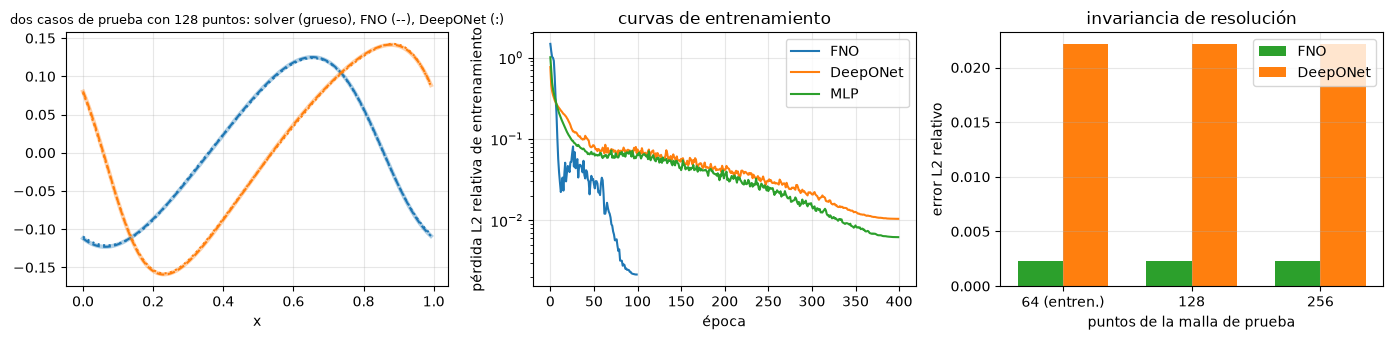

In [11]:
class SpectralConv1d(nn.Module):
    def __init__(self, cin, cout, modes):
        super().__init__()
        self.modes = modes
        self.w = nn.Parameter(torch.randn(cin, cout, modes, dtype=torch.cfloat) / (cin * cout) ** 0.5 * 0.5)
    def forward(self, x):                                       # x: (lote, canales, N)
        xf = torch.fft.rfft(x)
        out = torch.zeros(x.shape[0], self.w.shape[1], xf.shape[-1], dtype=torch.cfloat)
        out[:, :, :self.modes] = torch.einsum("bim,iom->bom", xf[:, :, :self.modes], self.w)
        return torch.fft.irfft(out, n=x.shape[-1])

class FNO1d(nn.Module):
    def __init__(self, width=24, modes=12, layers=4):
        super().__init__()
        self.lift = nn.Conv1d(2, width, 1)
        self.spec = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(layers)])
        self.pw = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(layers)])
        self.proj = nn.Sequential(nn.Conv1d(width, 96, 1), nn.GELU(), nn.Conv1d(96, 1, 1))
    def forward(self, u0):                                      # u0: (lote, N), N cualquiera
        N = u0.shape[1]; grid = (torch.arange(N, dtype=torch.float32) / N).expand(u0.shape[0], N)
        h = self.lift(torch.stack([u0, grid], 1))
        for s, p in zip(self.spec, self.pw):
            h = torch.nn.functional.gelu(s(h) + p(h))
        return self.proj(h)[:, 0]

class DeepONet(nn.Module):
    def __init__(self, m=64, p=64, h=128):
        super().__init__()
        self.m = m; self.branch = mlp([m, h, h, p], nn.GELU); self.trunk = mlp([3, h, h, p], nn.GELU); self.b0 = nn.Parameter(torch.zeros(1))
    def forward(self, u0):                                      # la rama lee m sensores fijos, el tronco cualquier número de puntos de consulta
        N = u0.shape[1]; sensors = u0[:, ::N // self.m]
        x = torch.arange(N, dtype=torch.float32) / N
        tf = torch.stack([torch.sin(2 * math.pi * x), torch.cos(2 * math.pi * x), torch.sin(4 * math.pi * x)], 1)
        return self.branch(sensors) @ self.trunk(tf).T + self.b0

class MLPOperator(nn.Module):
    def __init__(self, n=64, h=256):
        super().__init__(); self.net = mlp([n, h, h, h, n], nn.GELU)
    def forward(self, u0): return self.net(u0)

def rel_loss(pred, true):
    return (torch.linalg.norm(pred - true, dim=1) / torch.linalg.norm(true, dim=1)).mean()

def fit_operator(model, epochs=100, bs=50, lr=3e-3, seed=0):
    torch.manual_seed(seed)
    X = torch.tensor(U0_tr, dtype=torch.float32); Y = torch.tensor(UT_tr, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * (len(X) // bs))
    t_start = time.perf_counter(); curve = []
    for ep in range(epochs):
        perm = torch.randperm(len(X)); tot = 0.0
        for i in range(0, len(X) - bs + 1, bs):
            idx = perm[i:i + bs]; opt.zero_grad()
            loss = rel_loss(model(X[idx]), Y[idx]); loss.backward(); opt.step(); sched.step(); tot += float(loss)
        curve.append(tot / (len(X) // bs))
    return time.perf_counter() - t_start, curve

models = {"FNO": FNO1d(), "DeepONet": DeepONet(), "MLP": MLPOperator()}
train_sec, curves = {}, {}
for name, mdl in models.items():
    torch.manual_seed(0)
    n_par = sum(p.numel() if not p.is_complex() else 2 * p.numel() for p in mdl.parameters())
    train_sec[name], curves[name] = fit_operator(mdl, epochs=100 if name == "FNO" else 400)
    print(f"{name:9s} {n_par:>8,d} parámetros reales, entrenada en {train_sec[name]:.0f} s, pérdida final de entrenamiento {curves[name][-1]:.4f}")

@torch.no_grad()
def predict(mdl, u0):
    return mdl(torch.tensor(u0, dtype=torch.float32)).numpy()

def mean_rel(pred, true):
    return float(np.mean(np.linalg.norm(pred - true, axis=1) / np.linalg.norm(true, axis=1)))

print("\nerror L2 relativo medio en 100 condiciones iniciales de prueba (malla de entrenamiento = 64 puntos)")
print(f"{'conjunto de prueba':22s} {'malla':>5} {'FNO':>8} {'DeepONet':>9} {'MLP':>8}")
table = {}
for name in ["in-distribution", "out of distribution"]:
    for N in [64, 128, 256]:
        u0_, uT_ = test[(name, N)]
        row = [mean_rel(predict(models["FNO"], u0_), uT_), mean_rel(predict(models["DeepONet"], u0_), uT_)]
        row.append(mean_rel(predict(models["MLP"], u0_), uT_) if N == 64 else float("nan"))
        table[(name, N)] = row
        print(f"{name:22s} {N:>5} {row[0]:>8.4f} {row[1]:>9.4f} {row[2]:>8.4f}" if N == 64 else f"{name:22s} {N:>5} {row[0]:>8.4f} {row[1]:>9.4f}      n/a")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
u0_, uT_ = test[("in-distribution", 128)]; xg = np.arange(128) / 128
for j, i in enumerate([0, 1]):
    ax[0].plot(xg, uT_[i], f"C{j}", lw=3, alpha=0.35); ax[0].plot(xg, predict(models["FNO"], u0_)[i], f"C{j}--"); ax[0].plot(xg, predict(models["DeepONet"], u0_)[i], f"C{j}:")
ax[0].set_title("dos casos de prueba con 128 puntos: solver (grueso), FNO (--), DeepONet (:)"); ax[0].set_xlabel("x"); ax[0].title.set_fontsize(9)
for name in models: ax[1].semilogy(curves[name], label=name)
ax[1].set_xlabel("época"); ax[1].set_ylabel("pérdida L2 relativa de entrenamiento"); ax[1].legend(); ax[1].set_title("curvas de entrenamiento")
w = 0.35
for j, (name, c) in enumerate([("FNO", "tab:green"), ("DeepONet", "tab:orange")]):
    ax[2].bar(np.arange(3) + (j - 0.5) * w, [table[("in-distribution", N)][j] for N in [64, 128, 256]], w, color=c, label=name)
ax[2].set_xticks(range(3)); ax[2].set_xticklabels(["64 (entren.)", "128", "256"]); ax[2].set_xlabel("puntos de la malla de prueba"); ax[2].set_ylabel("error L2 relativo"); ax[2].legend(); ax[2].set_title("invariancia de resolución")
plt.tight_layout(); plt.show()

**Lectura.** La FNO aprendió bien la aplicación solución: el error relativo medio con 100 condiciones iniciales nuevas fue 0.23 %, frente a 1.5 % del MLP simple y 2.2 % de la DeepONet (la referencia de "no hacer nada" es 0.88), con unos 60,000 pesos en la FNO y la DeepONet y 165,000 en el MLP. A las referencias se les dio cuatro veces más épocas para comparar a tiempo de entrenamiento aproximadamente igual (14 a 15 s frente a 25 s), y se corrió una semilla por modelo, así que el ranking es una medición y no una ley general. En las mallas más finas de 128 y 256 puntos el error de la FNO es el mismo, 0.23 %, lo cual es **invariancia de resolución**: la red nunca vio esas mallas. La DeepONet también da el mismo número en todas las mallas, pero por otra razón: solo lee sus 64 valores de sensores y la malla más fina no añade información, mientras que el MLP no puede aplicarse a otra malla en absoluto. Ojo con la afirmación para la FNO: nuestra solución tiene banda limitada, así que una malla más fina no contiene escalas finas nuevas y un error idéntico es lo esperable; no significaría que la red pueda inventar estructura no resuelta. **Fuera de la distribución** (más modos, decaimiento espectral más lento, mayor amplitud) todos los modelos empeoran: la FNO a 5.8 % (25 veces su propio error dentro de la distribución), el MLP a 15 % y la DeepONet a 19 %. Un operador neuronal solo es tan bueno como la familia de entradas con que se entrenó.

### Velocidad frente al solver

La promesa de un sustituto es la velocidad. Medimos una ejecución del solver (una condición inicial, 128 puntos), el solver sobre un lote de 100 condiciones iniciales (está vectorizado, así que es una referencia fuerte) y la FNO sobre un lote de 100. Luego contamos cuántas soluciones hacen falta para que se pague toda la inversión (generar datos y entrenar).

In [12]:
u0_, uT_ = test[("in-distribution", 128)]
_, t_single = timed(lambda: burgers_solve(u0_[:1]), reps=5)
_, t_batch = timed(lambda: burgers_solve(u0_), reps=3)
x_t = torch.tensor(u0_, dtype=torch.float32)
with torch.no_grad():
    _, t_fno = timed(lambda: models["FNO"](x_t), reps=50)
    _, t_don = timed(lambda: models["DeepONet"](x_t), reps=50)
per = {"solver, un caso cada vez": t_single, "solver, lote de 100 (por caso)": t_batch / 100, "FNO, lote de 100 (por caso)": t_fno / 100, "DeepONet, lote de 100 (por caso)": t_don / 100}
for k_, v in per.items(): print(f"{k_:36s} {v*1e3:>9.3f} ms")
print(f"aceleración de la FNO: {t_single / (t_fno / 100):.0f} x frente al solver de uno en uno, {t_batch / t_fno:.1f} x frente al solver por lotes")
invest = T_GEN + train_sec["FNO"]
print(f"inversión: generación de datos {T_GEN:.1f} s + entrenamiento de la FNO {train_sec['FNO']:.0f} s = {invest:.0f} s")
print(f"punto de equilibrio: {invest / (t_batch / 100 - t_fno / 100):.0f} soluciones nuevas frente al solver por lotes, {invest / (t_single - t_fno / 100):.0f} frente al solver de uno en uno")

solver, un caso cada vez                34.770 ms
solver, lote de 100 (por caso)           1.804 ms
FNO, lote de 100 (por caso)              0.114 ms
DeepONet, lote de 100 (por caso)         0.004 ms
aceleración de la FNO: 304 x frente al solver de uno en uno, 15.8 x frente al solver por lotes
inversión: generación de datos 1.5 s + entrenamiento de la FNO 25 s = 26 s
punto de equilibrio: 15449 soluciones nuevas frente al solver por lotes, 753 frente al solver de uno en uno


**Lectura.** Frente al solver de uno en uno (35 ms por caso) la FNO es unas 330 veces más rápida por caso; frente a nuestro solver ejecutado sobre un lote de 100 a la vez (1.8 ms por caso, porque NumPy vectoriza sobre el lote) es solo unas 17 veces más rápida, y el número de la DeepONet es aún menor porque es una red muy pequeña. Invertir 27 s (generación de datos 1.5 s, entrenamiento 25 s) se amortiza tras unos 760 casos si de otro modo llamarías al solver caso por caso, y tras unos 15,800 casos frente al solver por lotes. Los dos números muestran con qué facilidad una "aceleración" depende de la referencia, que es la advertencia de McGreivy y Hakim (2024). El escenario además favorece al solver: es un problema unidimensional que tarda 35 ms. Para un solver tridimensional que necesita horas, las mismas razones significan días de cálculo ahorrados, que es donde realmente se usan los sustitutos neuronales; pero entonces el conjunto de entrenamiento necesita cientos o miles de esas ejecuciones caras, y la garantía de precisión es solo estadística. Los tiempos provienen de una máquina compartida y varían.

## 8. Qué herramienta para qué problema

| Situación | Mejor primera opción | Por qué | Qué puede salir mal |
|---|---|---|---|
| Problema directo bien planteado, ecuación y geometría conocidas, una o pocas ejecuciones | **solver clásico** | preciso, con estimaciones de error y décadas de verificación (sección 2) | el coste crece rápido en 3D y en problemas multiescala |
| Muchas consultas de la misma familia (bucles de diseño, incertidumbre, control en tiempo real), un solver que puedes ejecutar miles de veces | **operador neuronal (sustituto)** | una pasada hacia delante por caso (sección 7) | necesita un conjunto de entrenamiento grande del solver; la precisión solo está garantizada cerca de la distribución de entrenamiento; no hay garantía de que se cumplan las leyes de conservación |
| Unas pocas mediciones ruidosas y una ecuación en la que se confía | **PINN** (datos más residuo) | la física regulariza y extrapola (sección 3) | el entrenamiento es frágil (sección 6); hay que ajustar pesos |
| Coeficiente desconocido en una ecuación conocida | **ajuste inverso clásico si tienes un solver, PINN si no** (o si el modelo es incómodo de derivar) | sección 5: con un solver y el modelo correcto, los mínimos cuadrados fueron al menos igual de buenos | la PINN es más lenta por ajuste; el error del modelo sesga a ambos |
| Geometría difícil de mallar, o ecuación solo parcialmente conocida | **PINN o un híbrido** | sin malla; la ecuación puede usarse como restricción blanda | sin garantía de convergencia |
| Existe un buen solver pero es demasiado grueso o lento en un punto (cierre, física subescala) | **híbrido**: conservar el solver, aprender el término que falta o una corrección (un "cierre neuronal", solvers diferenciables) | conserva del solver la conservación y la estabilidad, aprende solo lo desconocido | la parte aprendida debe ser estable dentro del bucle del solver |
| Sin ecuación, muchos datos (tiempo atmosférico, proteínas) | **gran modelo basado en datos**, validado frente a la referencia física | sección 9 | sucesos fuera de la distribución, evidencia sobre todo en benchmarks |

De este cuaderno salen dos reglas prácticas. Primera: **da siempre la referencia del solver** a igual precisión (la sección 2 da la plantilla: error y segundos). Segunda: **mide con casos con los que el modelo no se entrenó**: una condición inicial nueva, un parámetro nuevo, una malla más fina (sección 7).

## 9. Grandes modelos científicos: qué está establecido

Las mismas ideas, a una escala que un portátil no alcanza, están detrás de varios de los resultados más visibles del aprendizaje automático en la ciencia. Resumimos qué está establecido y qué no; cada afirmación está en el artículo citado, donde puedes comprobar la evidencia.

* **Predicción meteorológica a medio plazo.** **FourCastNet** (Pathak et al., 2022) usa un operador neuronal de Fourier adaptativo (un pariente de la FNO de la sección 7) entrenado con décadas de datos de reanálisis (ERA5, la reconstrucción global del tiempo pasado); **Pangu-Weather** (Bi et al., 2023) usa un transformer 3D específico de la Tierra; **GraphCast** (Lam et al., 2023) usa una red neuronal de grafos sobre una malla multiescala (la idea del módulo 08 de Neural Networks 1002). Los tres pronostican el tiempo global varios días por adelantado en segundos a minutos con un acelerador, y el artículo de GraphCast informa de un error menor que el del principal sistema determinista operativo en la mayoría de los objetivos de verificación probados. Establecido: habilidad en benchmarks estándar para pronósticos deterministas hasta unos diez días. Menos establecido: sucesos extremos y situaciones raras fuera del periodo de entrenamiento, consistencia física de los campos e incertidumbre (un centro de predicción ejecuta conjuntos; la mayoría de estos modelos dan una sola trayectoria, aunque versiones posteriores añaden salida probabilística). Se entrenan con un reanálisis basado en física, así que dependen de los modelos numéricos que esperan complementar.
* **Estructura de proteínas.** **AlphaFold 2** (Jumper et al., 2021) predijo estructuras con una precisión comparable a la experimental en la evaluación ciega CASP14. Es un modelo basado en datos con estructura geométrica incorporada, y no es una PINN. Establecido: predicción precisa de estructura para muchas proteínas de una sola cadena; menos establecido: dinámica, efectos de mutaciones y cambios de conformación.
* **Materiales.** **GNoME** (Merchant et al., 2023) usó redes de grafos y aprendizaje activo para proponer millones de cristales candidatos. El número afirmado de materiales estables nuevos ha sido cuestionado: una perspectiva de Cheetham y Seshadri (2024) sostiene que muchos candidatos son químicamente inverosímiles o no son nuevos, un recordatorio de que una estabilidad predicha no es un material sintetizado.
* **Dónde están las PINN.** La revisión de Karniadakis et al. (2021) es una entrada equilibrada. Los artículos escépticos (Grossmann et al., 2024; McGreivy y Hakim, 2024) encontraron que cuando una PINN se compara con justicia con un solver clásico bien ajustado, el solver suele ganar en problemas directos. Las PINN son más fuertes donde hay que fusionar datos y física o el problema es inverso.

**En qué se diferencia nuestro juguete de estos sistemas.** Resolvemos problemas unidimensionales con redes de unos pocos miles de pesos y datos producidos en segundos por nuestro propio solver; los sistemas anteriores trabajan en tres dimensiones más tiempo, con miles de millones de datos y semanas de acelerador, y sus errores se juzgan frente a observaciones de un mundo real desordenado, no frente a un solver que escribimos nosotros.

## 10. Ideas clave, ejercicios, referencias

**Ideas clave**

* Una **PINN** pone la ecuación en la pérdida: la diferenciación automática de la red respecto de sus entradas da el residuo. Para el oscilador y la ecuación del calor su error osciló entre 3e-4 y 0.12 según los pesos, las restricciones y la semilla, e incluso las mejores ejecuciones fueron superadas por el **solver de diferencias finitas, que fue más preciso y miles de veces más rápido** (secciones 2 y 4). Una PINN no es un mejor solver para un problema directo bien planteado.
* **Los pesos de la pérdida y las restricciones importan.** El peso de las condiciones frente a la ecuación cambió el error en uno a dos órdenes de magnitud; una **restricción dura** elimina un término y fue la mejor opción en la ecuación del calor, y los **pesos adaptativos** eliminan la adivinanza de la escala pero no superaron a un peso bien elegido (secciones 3, 4, 6.2).
* Las PINN compensan donde **los datos son escasos y la física es conocida**: con 8 puntos ruidosos, la red solo con datos se equivocó fuera de la zona con datos (error superior a 1) y la red de física más datos estuvo dentro de un 11 % aproximadamente (sección 3). En el **problema inverso** nuestra PINN estuvo sesgada (40 % de error en la difusividad en todos los niveles de ruido) mientras que los mínimos cuadrados clásicos con la misma física estuvieron entre 0.1 % y 5 % y más de 100 veces más rápidos (sección 5).
* **Los modos de fallo son reales y medibles**: sesgo espectral (los rasgos de Fourier ayudaron mucho si la escala era la correcta y perjudicaron si no), desequilibrio de la pérdida (pesos adaptativos) y problemas rígidos (los rasgos de Fourier en el tiempo ayudaron 25 veces con $\beta=10$, el entrenamiento causal no); ninguno es una garantía (sección 6).
* Un **operador neuronal** aprende una familia de soluciones. La **FNO** alcanzó 0.2 % de error con condiciones iniciales nuevas (la DeepONet y el MLP 2 % y 1.5 %), lo mantuvo en mallas que nunca había visto (invariancia de resolución, con la salvedad de que nuestras soluciones tienen banda limitada) y fue 330 veces más rápida por caso que un solver de uno en uno; pero necesita un solver para producir sus datos, empeora 25 veces fuera de la distribución y frente a un solver *por lotes* la ganancia fue de 17 veces (sección 7).
* La decisión es una tabla, no un eslogan: solver para una ejecución bien planteada, operador neuronal para muchas consultas de una familia, PINN para datos escasos más física conocida, híbrido cuando solo una parte es desconocida (sección 8).
* Todos los números provienen de problemas diminutos con una a tres semillas; muestran mecanismos y órdenes de magnitud, no resultados de benchmark.

**Ejercicios**

1. En la sección 3 cambia el coeficiente de amortiguamiento a $\zeta=0.02$ y el rango de tiempo a $[0,30]$. ¿La PINN sigue encontrando la solución? Prueba los pesos causales de la sección 6.3 sobre el residuo del oscilador (en una prueba rápida nuestra dieron solo una mejora modesta en $[0,10]$).
2. Añade el **problema inverso** del oscilador: observa 40 puntos ruidosos de $x(t)$ y haz de $\zeta$ un parámetro entrenable (como $\log\zeta$). Compara con `scipy.optimize.curve_fit` sobre la solución exacta, en función del ruido.
3. En la sección 4 sustituye la activación tanh por un seno (una **SIREN**, sinusoidal representation network) o por ReLU. ¿Por qué falla una red ReLU en una EDP de segundo orden? (Calcula su segunda derivada.)
4. Cambia la condición inicial de la difusión a $\sin(5\pi x)$. ¿Cómo cambia el error de la PINN, y ayuda una entrada con rasgos de Fourier?
5. Sustituye los puntos de colocación aleatorios de la sección 4 por una malla fija de 1500 puntos. ¿Cuál es más precisa con el mismo número de pasos, y por qué?
6. En la sección 5 usa 50 mediciones en lugar de 300. ¿Dónde se rompe antes el ajuste clásico? Quita el favor al ajuste clásico (ajusta $u_0$ con solo dos términos seno) y mira qué le hace un perfil equivocado a $\nu$.
7. En la sección 6.3 barre $\varepsilon\in\{0.1,1,10\}$ para $\beta=30$ y grafica los pesos finales por intervalo. ¿Qué hace un $\varepsilon$ muy grande con el tiempo de entrenamiento?
8. En la sección 7 entrena la FNO con 100, 300 y 1000 condiciones iniciales y grafica el error de prueba frente al número de pares de entrenamiento. ¿Dónde deja de mejorar?
9. Entrena la FNO con $K=4$ y $K=24$ modos. ¿Por qué $K=24$ no ayuda necesariamente en una malla de 64 puntos?
10. Usa la FNO de forma **autorregresiva**: entrénala para un paso de tiempo de 0.1 y aplícala diez veces para llegar a $T=1$. Compara con el operador de un solo paso: ¿cuál acumula más error? Así se despliegan los modelos meteorológicos.
11. Construye un **híbrido**: ejecuta el solver de Burgers en una malla gruesa de 32 puntos y entrena una red pequeña que corrija su salida hacia la solución de 128 puntos. ¿Cuánta precisión ganas frente al solver grueso a secas?
12. Añade una PINN al operador neuronal: suma a la pérdida de la FNO el residuo de la ecuación de Burgers, calculado con diferencias finitas sobre la salida (un "operador neuronal informado por la física"). ¿Ayuda cuando el conjunto de entrenamiento es pequeño (100 pares)?

**Referencias**

* Raissi, M., Perdikaris, P. and Karniadakis, G. E. (2019). Physics-informed neural networks: a deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations. *Journal of Computational Physics* 378, 686-707: https://doi.org/10.1016/j.jcp.2018.10.045
* Karniadakis, G. E., Kevrekidis, I. G., Lu, L., Perdikaris, P., Wang, S. and Yang, L. (2021). Physics-informed machine learning. *Nature Reviews Physics* 3, 422-440: https://doi.org/10.1038/s42254-021-00314-5
* Lu, L., Jin, P., Pang, G., Zhang, Z. and Karniadakis, G. E. (2021). Learning nonlinear operators via DeepONet based on the universal approximation theorem of operators. *Nature Machine Intelligence* 3, 218-229; preprint arXiv:1910.03193: https://arxiv.org/abs/1910.03193
* Li, Z., Kovachki, N., Azizzadenesheli, K., Liu, B., Bhattacharya, K., Stuart, A. and Anandkumar, A. (2021). Fourier neural operator for parametric partial differential equations. *ICLR*. arXiv:2010.08895: https://arxiv.org/abs/2010.08895
* Wang, S., Teng, Y. and Perdikaris, P. (2021). Understanding and mitigating gradient flow pathologies in physics-informed neural networks. *SIAM Journal on Scientific Computing* 43(5), A3055-A3081. arXiv:2001.04536: https://arxiv.org/abs/2001.04536
* Wang, S., Sankaran, S. and Perdikaris, P. (2022). Respecting causality is all you need for training physics-informed neural networks. arXiv:2203.07404: https://arxiv.org/abs/2203.07404
* Krishnapriyan, A. S., Gholami, A., Zhe, S., Kirby, R. M. and Mahoney, M. W. (2021). Characterizing possible failure modes in physics-informed neural networks. *NeurIPS*. arXiv:2109.01050: https://arxiv.org/abs/2109.01050
* Tancik, M. et al. (2020). Fourier features let networks learn high frequency functions in low dimensional domains. *NeurIPS*. arXiv:2006.10739: https://arxiv.org/abs/2006.10739
* Grossmann, T. G., Komorowska, U. J., Latz, J. and Schonlieb, C.-B. (2024). Can physics-informed neural networks beat the finite element method? *IMA Journal of Applied Mathematics* 89(1), 143-174: https://doi.org/10.1093/imamat/hxae011
* McGreivy, N. and Hakim, A. (2024). Weak baselines and reporting biases lead to overoptimism in machine learning for fluid-related partial differential equations. *Nature Machine Intelligence* 6, 1256-1269: https://doi.org/10.1038/s42256-024-00897-5
* Lam, R. et al. (2023). Learning skillful medium-range global weather forecasting (GraphCast). *Science* 382(6677), 1416-1421: https://doi.org/10.1126/science.adi2336
* Pathak, J. et al. (2022). FourCastNet: a global data-driven high-resolution weather model using adaptive Fourier neural operators. arXiv:2202.11214: https://arxiv.org/abs/2202.11214
* Bi, K. et al. (2023). Accurate medium-range global weather forecasting with 3D neural networks (Pangu-Weather). *Nature* 619, 533-538; preprint arXiv:2211.02556: https://arxiv.org/abs/2211.02556
* Jumper, J. et al. (2021). Highly accurate protein structure prediction with AlphaFold. *Nature* 596, 583-589: https://doi.org/10.1038/s41586-021-03819-2
* Merchant, A. et al. (2023). Scaling deep learning for materials discovery (GNoME). *Nature* 624, 80-85: https://doi.org/10.1038/s41586-023-06735-9
* Cheetham, A. K. and Seshadri, R. (2024). Artificial intelligence driving materials discovery? Perspective on the article: Scaling deep learning for materials discovery. *Chemistry of Materials* 36(8), 3490-3495: https://doi.org/10.1021/acs.chemmater.4c00643
* LeVeque, R. J. (2007). *Finite difference methods for ordinary and partial differential equations*. SIAM: https://doi.org/10.1137/1.9780898717839
* Cox, S. M. and Matthews, P. C. (2002). Exponential time differencing for stiff systems. *Journal of Computational Physics* 176(2), 430-455 (integrating-factor and exponential Runge-Kutta schemes used for spectral solvers): https://doi.org/10.1006/jcph.2002.6995